<a id=toc></a>
<h1 style="padding: 35px;color:white;margin:10;font-size:200%;text-align:center;display:fill;border-radius:10px;overflow:hidden;background-image: url(https://i.postimg.cc/fTDmwnkQ/Miaka.png); background-size: 100% auto;background-position: 0px 0px; 

<h0 style="color:white; text-align:center; line-height:1;">
  <b>Building a Bayesian Network-Based Query System for Retail Sales Analysis✨</b><br>

  <span style="font-size:32px;; margin-top:-1px;display:inline-block">
    <b>Group 5</b>
  </span><br>

  <span style="font-size:20px; margin-top:-20px; display:inline-block;">
    Chen Qianqi (2330034001) &#x3000;Hou Chuqing (2330034014)
  </span><br>

  <span style="font-size:20px; margin-top:-20px; display:inline-block;">
    Huang Siqi (2330034020)&#x3000;Li Guangmei (2330034025)
  </span><br>

  <span style="font-size:20px; margin-top:-20px; display:inline-block;">
    Li Minghao (2330034027)&#x3000;Liang Yirui (2330034030)
  </span><br>



</h1>

<div style="padding: 4px;color:white;margin:10;font-size:200%;text-align:center;display:fill;border-radius:10px;overflow:hidden;background-image: url(https://i.postimg.cc/fTDmwnkQ/Miaka.png); background-size: 100% auto;"></div>

<div style="text-align:center;">
  <h1><b>Table of contents</b></h1>
</div>

- [**1 | Introduction**](#1)
- [ **2 | Data Preprocessing + Exploratory Data Analysis(EDA)**](#2)
- [ **3 | Preset DAG**](#3)
- [ **4 | Maximum Likelihood Estimation(MLE)**](#4)   
- [ **5 | Model Design**](#5) 
- [ **6 | Training Pipeline**](#6) 
   - [ **6.1 Model Training for Binary Classification (Stage 1)**](#61)  
   - [ **6.2 Model Comparison for Binary Classification(Stage 1)**](#62)  
   - [ **6.3 Model Training for Multi-class Classification (Stage 2)**](#63)  
   - [ **6.4 Model Comparison for Multi-class Classification(Stage 2)**](#64)  
- [ **7 |  Two-stage Fusion and Evaluation**](#7) 
   - [ **7.1 Two-stage Fusion (Two Version)**](#71)  
   - [ **7.2 Evaluation**](#72)  
- [ **8 | Comprehensive Evaluation**](#8) 
- [ **9 | Future Work**](#9) 


   

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator, ExpectationMaximization
from pgmpy.inference import BeliefPropagation

d:\Anaconda3\envs\BN\Lib\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [2]:
train = pd.read_csv("data/train.csv")
store = pd.read_csv("data/store.csv")

df = train.merge(store, on="Store", how="left")

df.head()

C:\Users\gidle\AppData\Local\Temp\ipykernel_20388\3216638756.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("data/train.csv")


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [3]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval'],
      dtype='object')

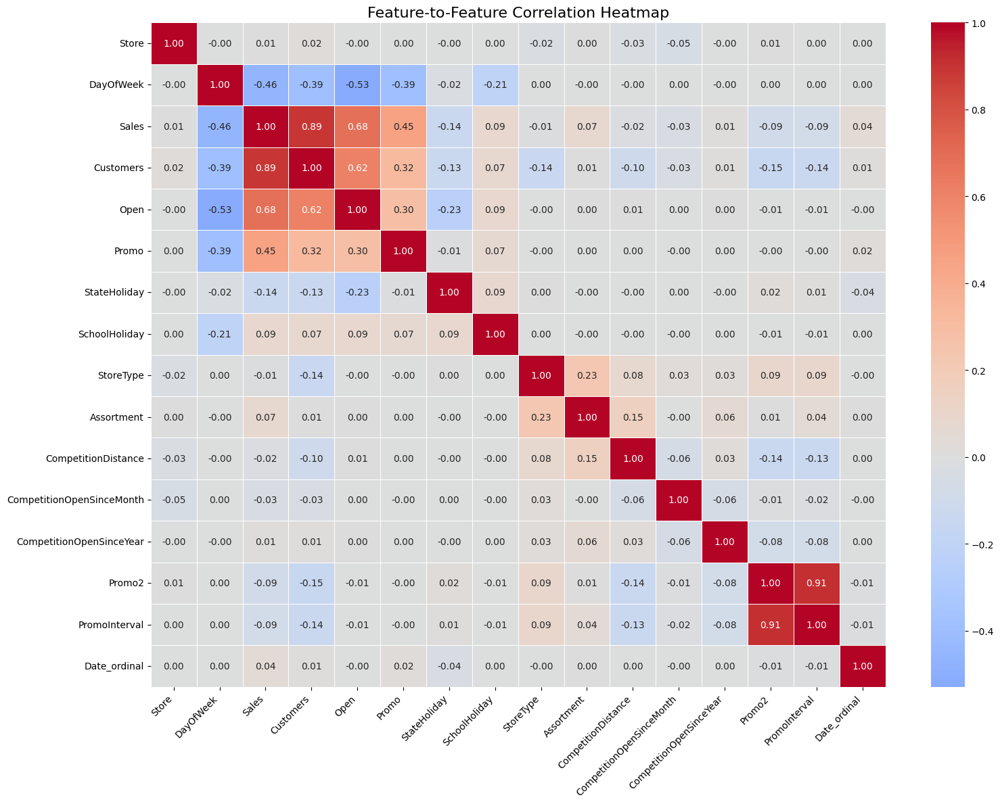

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Copy data to avoid changing the original dataframe
heatmap_data = df.copy()

# Drop columns that should not be included in the heatmap
cols_to_drop = ["Promo2SinceWeek", "Promo2SinceYear"]

heatmap_data = heatmap_data.drop(
    columns=[col for col in cols_to_drop if col in heatmap_data.columns]
)

# Convert Date column into numeric ordinal value
if "Date" in heatmap_data.columns:
    heatmap_data["Date"] = pd.to_datetime(heatmap_data["Date"])
    heatmap_data["Date_ordinal"] = heatmap_data["Date"].map(pd.Timestamp.toordinal)
    heatmap_data = heatmap_data.drop(columns=["Date"])

# Encode non-numeric columns as category codes
for col in heatmap_data.columns:
    if heatmap_data[col].dtype == "object" or str(heatmap_data[col].dtype) == "category":
        heatmap_data[col] = heatmap_data[col].astype("category").cat.codes

# Compute correlation matrix
corr_matrix = heatmap_data.corr()

# Plot heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Feature-to-Feature Correlation Heatmap", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
# ==============================
# Cell 4: Basic preprocessing preparation
# ==============================

# Convert Date to datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Convert Date into month-level category for Bayesian Network
# Keep the column name as "Date" as required
df["Date"] = df["Date"].dt.month

# Make StateHoliday consistent as string
df["StateHoliday"] = df["StateHoliday"].astype(str)

# Check selected variables
selected_cols = [
    "Date",
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "Open",
    "CompetitionDistance",
    "Sales",
    "Assortment"
]

df[selected_cols].head()

,Date,Promo,Customers,DayOfWeek,StateHoliday,SchoolHoliday,Open,CompetitionDistance,Sales,Assortment
0,7,1,555,5,0,1,1,1270.0,5263,a
1,7,1,625,5,0,1,1,570.0,6064,a
2,7,1,821,5,0,1,1,14130.0,8314,a
3,7,1,1498,5,0,1,1,620.0,13995,c
4,7,1,559,5,0,1,1,29910.0,4822,a


In [6]:
# ==============================
# Cell 5: Select variables and check missing values before discretisation
# ==============================

selected_cols = [
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "Open",
    "CompetitionDistance",
    "Sales",
    "Assortment"
]

raw_bn_df = df[selected_cols].copy()

print("Missing values before discretisation:")
print(raw_bn_df.isna().sum())

print("\nTotal missing values before discretisation:")
print(raw_bn_df.isna().sum().sum())

Missing values before discretisation:
Promo                     0
Customers                 0
DayOfWeek                 0
StateHoliday              0
SchoolHoliday             0
Open                      0
CompetitionDistance    2642
Sales                     0
Assortment                0
dtype: int64

Total missing values before discretisation:
2642


In [7]:
# ==============================
# Cell 6: Handle missing CompetitionDistance by dropping missing rows
# ==============================

print("Missing CompetitionDistance before dropping:")
print(raw_bn_df["CompetitionDistance"].isna().sum())

rows_before = len(raw_bn_df)

# Drop rows where CompetitionDistance is missing
raw_bn_df = raw_bn_df.dropna(subset=["CompetitionDistance"]).copy()

rows_after = len(raw_bn_df)

print("\nMissing CompetitionDistance after dropping:")
print(raw_bn_df["CompetitionDistance"].isna().sum())

print("\nRows before dropping:", rows_before)
print("Rows after dropping:", rows_after)
print("Dropped rows:", rows_before - rows_after)

Missing CompetitionDistance before dropping:
2642

Missing CompetitionDistance after dropping:
0

Rows before dropping: 1017209
Rows after dropping: 1014567
Dropped rows: 2642


In [8]:
# Cell 8: Discretisation without changing column names
bn_data = raw_bn_df.copy()

bin_settings = {}


# ------------------------------
# Helper 1: zero + qcut three bins
# ------------------------------
def zero_plus_qcut(series, labels_nonzero):
    """
    Put 0 into a separate category.
    Split non-zero values into three quantile-based bins.
    """
    result = pd.Series(index=series.index, dtype="object")
    
    zero_mask = series == 0
    nonzero_mask = series != 0
    
    result.loc[zero_mask] = "Zero"
    
    nonzero_values = series.loc[nonzero_mask]
    
    binned_nonzero, bins = pd.qcut(
        nonzero_values,
        q=3,
        labels=labels_nonzero,
        duplicates="drop",
        retbins=True
    )
    
    result.loc[nonzero_mask] = binned_nonzero.astype(str)
    
    full_bins = np.concatenate(([0], bins))
    
    return result, full_bins


# ------------------------------
# Helper 2: zero + median ± 30% for Sales
# ------------------------------
def zero_plus_sales_median_threshold(series):
    """
    Put 0 into a separate category.
    For non-zero Sales:
    Low    <= median * 0.7
    Medium <= median * 1.3
    High   > median * 1.3
    """
    result = pd.Series(index=series.index, dtype="object")
    
    zero_mask = series == 0
    nonzero_mask = series != 0
    
    result.loc[zero_mask] = "Zero"
    
    nonzero_values = series.loc[nonzero_mask]
    median_value = nonzero_values.median()
    
    lower_threshold = median_value * 0.7
    upper_threshold = median_value * 1.3
    
    result.loc[
        nonzero_mask & (series <= lower_threshold)
    ] = "Low"
    
    result.loc[
        nonzero_mask & (series > lower_threshold) & (series <= upper_threshold)
    ] = "Medium"
    
    result.loc[
        nonzero_mask & (series > upper_threshold)
    ] = "High"
    
    bins = np.array([
        0,
        lower_threshold,
        upper_threshold,
        np.inf
    ])
    
    return result, bins, median_value, lower_threshold, upper_threshold


# ------------------------------
# Customers: Zero + Low / Medium / High
# ------------------------------
bn_data["Customers"], customers_bins = zero_plus_qcut(
    raw_bn_df["Customers"],
    labels_nonzero=["Low", "Medium", "High"]
)

bin_settings["Customers"] = {
    "bins": customers_bins,
    "labels": ["Zero", "Low", "Medium", "High"]
}


# ------------------------------
# Sales: Zero + median ± 30%
# ------------------------------
(
    bn_data["Sales"],
    sales_bins,
    sales_median,
    sales_lower_threshold,
    sales_upper_threshold
) = zero_plus_sales_median_threshold(raw_bn_df["Sales"])

bin_settings["Sales"] = {
    "bins": sales_bins,
    "labels": ["Zero", "Low", "Medium", "High"],
    "median": sales_median,
    "lower_threshold": sales_lower_threshold,
    "upper_threshold": sales_upper_threshold
}


# ------------------------------
# CompetitionDistance: Near / Medium / Far
# ------------------------------
bn_data["CompetitionDistance"], competition_bins = pd.qcut(
    raw_bn_df["CompetitionDistance"],
    q=3,
    labels=["Near", "Medium", "Far"],
    duplicates="drop",
    retbins=True
)

bin_settings["CompetitionDistance"] = {
    "bins": competition_bins,
    "labels": ["Near", "Medium", "Far"]
}
# ------------------------------
# Convert all variables into category type
# ------------------------------
for col in bn_data.columns:
    bn_data[col] = bn_data[col].astype("category")


print("Sales median:", sales_median)
print("Sales lower threshold: median * 0.7 =", sales_lower_threshold)
print("Sales upper threshold: median * 1.3 =", sales_upper_threshold)

print("\nValue counts after discretisation:")
for col in ["Customers", "Sales", "CompetitionDistance"]:
    print(bn_data[col].value_counts())

bn_data.head()

Sales median: 6373.0
Sales lower threshold: median * 0.7 = 4461.099999999999
Sales upper threshold: median * 1.3 = 8284.9

Value counts after discretisation:
Customers
Low       282287
High      280591
Medium    279276
Zero      172413
Name: count, dtype: int64
Sales
Medium    466703
High      216842
Zero      172415
Low       158607
Name: count, dtype: int64
CompetitionDistance
Near      338971
Medium    338302
Far       337294
Name: count, dtype: int64


,Promo,Customers,DayOfWeek,StateHoliday,SchoolHoliday,Open,CompetitionDistance,Sales,Assortment
0,1,Low,5,0,1,1,Medium,Medium,a
1,1,Medium,5,0,1,1,Near,Medium,a
2,1,High,5,0,1,1,Far,High,a
3,1,High,5,0,1,1,Near,High,c
4,1,Low,5,0,1,1,Far,Medium,a


In [9]:
# ==============================
# Binning plots for discretised variables
# ==============================

import plotly.express as px

colors_blue = ["#132C33", "#264D58", "#17869E", "#51C4D3", "#B4DBE9"]
colors_dark = ["#1F1F1F", "#313131", "#636363", "#AEAEAE", "#DADADA"]
colors_green = ["#01411C", "#4B6F44", "#4F7942", "#74C365", "#D0F0C0"]

for feature in bin_settings.keys():
    temp = pd.DataFrame({
        feature: raw_bn_df[feature],
        "Bin Category": bn_data[feature].astype(str)
    }).dropna()

    fig = px.histogram(
        temp,
        x=feature,
        color="Bin Category",
        nbins=60,
        opacity=0.75,
        marginal="box",
        template="plotly_white",
        color_discrete_sequence=[
            colors_blue[2],
            colors_green[3],
            colors_blue[4],
            colors_green[1],
            colors_dark[3]
        ]
    )

    bins = bin_settings[feature]["bins"]

    # Draw meaningful boundaries only
    if feature in ["Customers", "Sales"]:
        boundaries = [0] + [
            b for b in bins[1:-1]
            if np.isfinite(b)
        ]
    else:
        boundaries = [
            b for b in bins[1:-1]
            if np.isfinite(b)
        ]

    for b in boundaries:
        fig.add_vline(
            x=b,
            line_width=1,
            line_dash="dot",
            line_color=colors_dark[1],
            opacity=0.8
        )

        fig.add_annotation(
            x=b,
            y=1,
            yref="paper",
            text=f"Boundary = {b:.2f}",
            showarrow=False,
            font_size=10,
            font_family="monospace",
            bgcolor="white"
        )

    fig.update_layout(
        font_family="monospace",
        title=dict(
            text=f"{feature} Discretisation / Binning Plot",
            x=0.5,
            y=0.95,
            font=dict(color=colors_dark[2], size=20)
        ),
        xaxis_title_text=feature,
        yaxis_title_text="Count",
        legend_title_text="Bin Category",
        bargap=0.25
    )

    fig.show()

In [10]:
# ==============================
# Count plots for categorical variables
# ==============================

categorical_features = [
    "Open",
    "Promo",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "Assortment"
]

for feature in categorical_features:
    temp = bn_data[feature].astype(str).value_counts().reset_index()
    temp.columns = [feature, "Count"]

    fig = px.bar(
        temp,
        x=feature,
        y="Count",
        template="plotly_white",
        color=feature,
        color_discrete_sequence=[
            colors_blue[2],
            colors_green[3],
            colors_blue[4],
            colors_green[1],
            colors_dark[3]
        ]
    )

    fig.update_layout(
        font_family="monospace",
        title=dict(
            text=f"{feature} Category Distribution",
            x=0.5,
            y=0.95,
            font=dict(color=colors_dark[2], size=22)
        ),
        xaxis_title_text=feature,
        yaxis_title_text="Count",
        showlegend=False
    )

    fig.show()

In [11]:
# ==============================
# Cell 9: Final data check after discretisation
# ==============================

print("Final missing values:")
print(bn_data.isna().sum())

print("\nTotal final missing values:")
print(bn_data.isna().sum().sum())

print("\nData types:")
print(bn_data.dtypes)

print("\nShape of final bn_data:")
print(bn_data.shape)

Final missing values:
Promo                  0
Customers              0
DayOfWeek              0
StateHoliday           0
SchoolHoliday          0
Open                   0
CompetitionDistance    0
Sales                  0
Assortment             0
dtype: int64

Total final missing values:
0

Data types:
Promo                  category
Customers              category
DayOfWeek              category
StateHoliday           category
SchoolHoliday          category
Open                   category
CompetitionDistance    category
Sales                  category
Assortment             category
dtype: object

Shape of final bn_data:
(1014567, 9)


In [12]:
# ==============================
# Cell 10: Define Updated Manual Domain DAG
# ==============================

edges = [
    ("Promo", "Customers"),
    ("DayOfWeek", "Customers"),
    ("StateHoliday", "Open"),
    ("SchoolHoliday", "Open"),
    ("SchoolHoliday", "Customers"),
    ("CompetitionDistance", "Customers"),
    ("Customers", "Sales"),
    ("Assortment", "Sales"),
    ("Promo", "Sales"),
    ("Open", "Promo"),
    ("Open", "Customers"),
    ("DayOfWeek", "Promo")
]

model = DiscreteBayesianNetwork(edges)

print("Nodes:")
print(list(model.nodes()))

print("\nEdges:")
for edge in model.edges():
    print(edge)

Nodes:
['Promo', 'Customers', 'DayOfWeek', 'StateHoliday', 'Open', 'SchoolHoliday', 'CompetitionDistance', 'Sales', 'Assortment']

Edges:
('Promo', 'Customers')
('Promo', 'Sales')
('Customers', 'Sales')
('DayOfWeek', 'Customers')
('DayOfWeek', 'Promo')
('StateHoliday', 'Open')
('Open', 'Promo')
('Open', 'Customers')
('SchoolHoliday', 'Open')
('SchoolHoliday', 'Customers')
('CompetitionDistance', 'Customers')
('Assortment', 'Sales')


In [13]:
# ==============================
# Cell 11: Check whether the graph is a valid DAG
# ==============================

manual_graph = nx.DiGraph(edges)

print("Is the manual graph a DAG?")
print(nx.is_directed_acyclic_graph(manual_graph))

Is the manual graph a DAG?
True


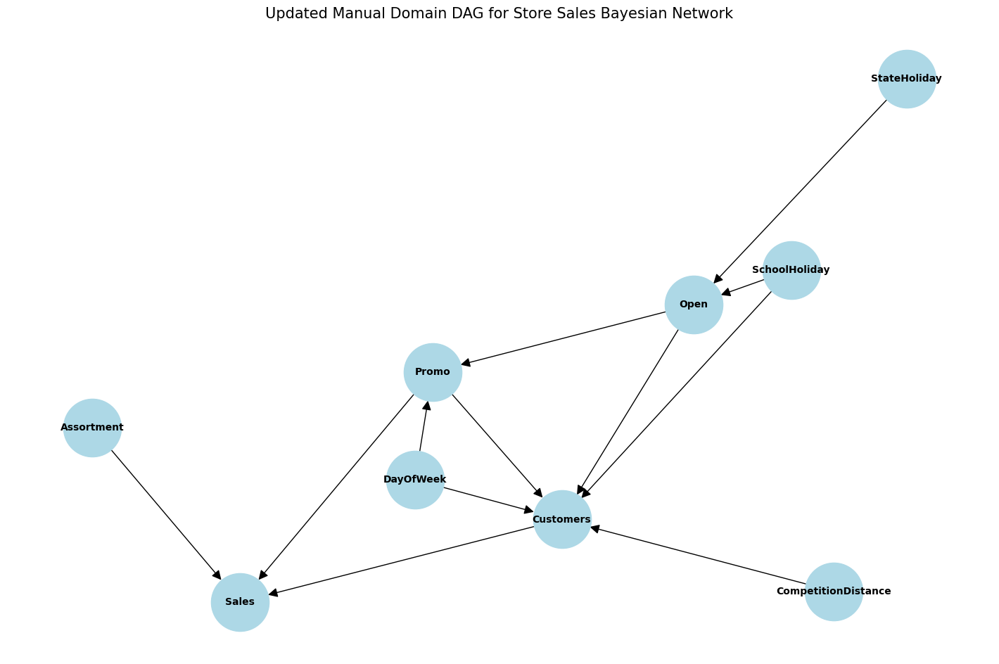

In [14]:
# ==============================
# Cell 12: Visualise Updated Manual Domain DAG
# ==============================

plt.figure(figsize=(14, 9))

pos = nx.spring_layout(manual_graph, seed=42)

nx.draw(
    manual_graph,
    pos,
    with_labels=True,
    node_size=3500,
    node_color="lightblue",
    font_size=10,
    font_weight="bold",
    arrowsize=20
)

plt.title("Updated Manual Domain DAG for Store Sales Bayesian Network", fontsize=15)
plt.show()

In [15]:
# ==============================
# Cell 13: Text summary of Updated Manual DAG relationships
# ==============================

manual_relationships = pd.DataFrame(
    edges,
    columns=["Parent Node", "Child Node"]
)

manual_relationships["Relationship"] = (
    manual_relationships["Parent Node"]
    + " influences "
    + manual_relationships["Child Node"]
)

manual_relationships

,Parent Node,Child Node,Relationship
0,Promo,Customers,Promo influences Customers
1,DayOfWeek,Customers,DayOfWeek influences Customers
2,StateHoliday,Open,StateHoliday influences Open
3,SchoolHoliday,Open,SchoolHoliday influences Open
4,SchoolHoliday,Customers,SchoolHoliday influences Customers
5,CompetitionDistance,Customers,CompetitionDistance influences Customers
6,Customers,Sales,Customers influences Sales
7,Assortment,Sales,Assortment influences Sales
8,Promo,Sales,Promo influences Sales
9,Open,Promo,Open influences Promo


In [16]:
# ==============================
# Cell 14: Parameter learning using MLE
# ==============================

mle = MaximumLikelihoodEstimator(model, bn_data)
cpds = mle.get_parameters()

model.add_cpds(*cpds)

print("Parameter learning method: MLE")

C:\Users\gidle\AppData\Local\Temp\ipykernel_20388\2356662675.py:5: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  mle = MaximumLikelihoodEstimator(model, bn_data)


Parameter learning method: MLE


In [17]:
# ==============================
# Cell 15: Check model validity
# ==============================

print("Model valid:", model.check_model())

Model valid: True


In [18]:
# ==============================
# Cell 16: Display all learned CPDs as pandas tables
# ==============================

import itertools
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)


def cpd_to_pandas(cpd):
    """
    Convert a pgmpy TabularCPD into a pandas DataFrame for clearer display.
    Works for both:
    - CPD without parents: P(X)
    - CPD with parents: P(X | Parents)
    """
    
    variable = cpd.variable
    variable_states = cpd.state_names[variable]
    
    values = cpd.get_values()
    
    # Evidence / parent variables
    evidence_vars = [var for var in cpd.variables if var != variable]
    
    # Case 1: no parent nodes
    if len(evidence_vars) == 0:
        df = pd.DataFrame(
            values,
            index=[f"{variable}={state}" for state in variable_states],
            columns=["Probability"]
        )
        return df
    
    # Case 2: has parent nodes
    evidence_states = [
        cpd.state_names[var]
        for var in evidence_vars
    ]
    
    column_combinations = list(itertools.product(*evidence_states))
    
    if len(evidence_vars) == 1:
        columns = [
            f"{evidence_vars[0]}={state_combo[0]}"
            for state_combo in column_combinations
        ]
    else:
        columns = pd.MultiIndex.from_tuples(
            column_combinations,
            names=evidence_vars
        )
    
    df = pd.DataFrame(
        values,
        index=[f"{variable}={state}" for state in variable_states],
        columns=columns
    )
    
    return df


cpds = {
    cpd.variable: cpd
    for cpd in model.get_cpds()
}

for k, v in cpds.items():
    print(f"CPD Table for variable: {k}")
    display(cpd_to_pandas(v))
    print("=" * 100)

CPD Table for variable: Promo


DayOfWeek         1                   2                   3            \
Open              0         1         0         1         0         1   
Promo=0    0.927842  0.438482  0.728664  0.464311  0.645239  0.462735   
Promo=1    0.072158  0.561518  0.271336  0.535689  0.354761  0.537265   

DayOfWeek        4                   5              6         7       
Open             0         1         0         1    0    1    0    1  
Promo=0    0.69122  0.449495  0.247113  0.479545  1.0  1.0  1.0  1.0  
Promo=1    0.30878  0.550505  0.752887  0.520455  0.0  0.0  0.0  0.0

CPD Table for variable: Customers


CompetitionDistance  Far                                               \
DayOfWeek              1                                                
Open                   0                        1                       
Promo                  0         1              0                   1   
SchoolHoliday          0    1    0    1         0         1         0   
Customers=High       0.0  0.0  0.0  0.0  0.133675  0.308228  0.470265   
Customers=Low        0.0  0.0  0.0  0.0  0.494849  0.343274  0.179413   
Customers=Medium     0.0  0.0  0.0  0.0  0.371477  0.348280  0.350323   
Customers=Zero       1.0  1.0  1.0  1.0  0.000000  0.000218  0.000000   

CompetitionDistance                                                    \
DayOfWeek                        2                                      
Open                             0                        1             
Promo                            0         1              0             
SchoolHoliday               1    0    1    0    1         0         1   
Customers=High       0.478013  0.0  0.0  0.0  0.0  0.116152  0.178660   
Customers=Low        0.158982  0.0  0.0  0.0  0.0  0.554347  0.501400   
Customers=Medium     0.363005  0.0  0.0  0.0  0.0  0.329439  0.319941   
Customers=Zero       0.000000  1.0  1.0  1.0  1.0  0.000062  0.000000   

CompetitionDistance                                                    \
DayOfWeek                                  3                            
Open                                       0                        1   
Promo                       1              0         1              0   
SchoolHoliday               0         1    0    1    0    1         0   
Customers=High       0.301680  0.282197  0.0  0.0  0.0  0.0  0.115154   
Customers=Low        0.307497  0.315084  0.0  0.0  0.0  0.0  0.544704   
Customers=Medium     0.390822  0.402719  0.0  0.0  0.0  0.0  0.340020   
Customers=Zero       0.000000  0.000000  1.0  1.0  1.0  1.0  0.000122   

CompetitionDistance                                                    \
DayOfWeek                                            4                  
Open                                                 0                  
Promo                                 1              0         1        
SchoolHoliday               1         0         1    0    1    0    1   
Customers=High       0.097132  0.237504  0.256915  0.0  0.0  0.0  0.0   
Customers=Low        0.586309  0.356382  0.325123  0.0  0.0  0.0  0.0   
Customers=Medium     0.316559  0.406064  0.417961  0.0  0.0  0.0  0.0   
Customers=Zero       0.000000  0.000050  0.000000  1.0  1.0  1.0  1.0   

CompetitionDistance                                                            \
DayOfWeek                                                    5                  
Open                        1                                0                  
Promo                       0                 1              0         1        
SchoolHoliday               0       1         0         1    0    1    0    1   
Customers=High       0.121075  0.1258  0.255764  0.305624  0.0  0.0  0.0  0.0   
Customers=Low        0.501464  0.4990  0.323468  0.271346  0.0  0.0  0.0  0.0   
Customers=Medium     0.377461  0.3750  0.420717  0.423030  0.0  0.0  0.0  0.0   
Customers=Zero       0.000000  0.0002  0.000051  0.000000  1.0  1.0  1.0  1.0   

CompetitionDistance                                                          \
DayOfWeek                                                      6              
Open                        1                                  0              
Promo                       0                   1              0          1   
SchoolHoliday               0         1         0         1    0    1     0   
Customers=High       0.178828  0.190631  0.298495  0.263622  0.0  0.0  0.25   
Customers=Low        0.402836  0.405660  0.261087  0.277765  0.0  0.0  0.25   
Customers=Medium     0.418336  0.403709  0.440418  0.458613  0.0  0.0  0.25   
Custom

CPD Table for variable: DayOfWeek


,Probability
DayOfWeek=1,0.142281
DayOfWeek=2,0.143200
DayOfWeek=3,0.143201
DayOfWeek=4,0.143377
DayOfWeek=5,0.143377
DayOfWeek=6,0.142281
DayOfWeek=7,0.142281


... (8 outputs left out)

CPD Table for variable: Sales


Assortment           a                                                         \
Customers         High                 Low              Medium           Zero   
Promo                0         1         0         1         0         1    0   
Sales=High    0.396556  0.701834  0.000270  0.006327  0.024927  0.168223  0.0   
Sales=Low     0.001110  0.000000  0.692175  0.262623  0.139442  0.023137  0.0   
Sales=Medium  0.602334  0.298166  0.307555  0.731026  0.835631  0.808640  0.0   
Sales=Zero    0.000000  0.000000  0.000000  0.000024  0.000000  0.000000  1.0   

Assortment                b                                                 \
Customers              High            Low           Medium      Zero        
Promo           1         0         1    0         1      0    1    0    1   
Sales=High    0.0  0.475929  0.528590  0.0  0.000000    0.0  0.0  0.0  0.0   
Sales=Low     0.0  0.117205  0.106238  1.0  0.857143    1.0  1.0  0.0  0.0   
Sales=Medium  0.0  0.406866  0.365172  0.0  0.000000    0.0  0.0  0.0  0.0   
Sales=Zero    1.0  0.000000  0.000000  0.0  0.142857    0.0  0.0  1.0  1.0   

Assortment           c                                                         \
Customers         High                 Low              Medium           Zero   
Promo                0         1         0         1         0         1    0   
Sales=High    0.561884  0.806196  0.001331  0.024301  0.080960  0.300304  0.0   
Sales=Low     0.000271  0.000027  0.490223  0.212100  0.057601  0.011494  0.0   
Sales=Medium  0.437845  0.193777  0.508446  0.763599  0.861439  0.688202  0.0   
Sales=Zero    0.000000  0.000000  0.000000  0.000000  0.000000  0.000000  1.0   

Assortment         
Customers          
Promo           1  
Sales=High    0.0  
Sales=Low     0.0  
Sales=Medium  0.0  
Sales=Zero    1.0

CPD Table for variable: Assortment


,Probability
Assortment=a,0.528053
Assortment=b,0.008175
Assortment=c,0.463772


In [19]:
# ==============================
# Cell 17: Evaluate Manual DAG using AIC
# ==============================

from pgmpy.estimators import AIC, HillClimbSearch

aic = AIC(bn_data)

manual_aic_score = aic.score(model)

print("Manual DAG AIC Score:", manual_aic_score)

Manual DAG AIC Score: -6736633.69542216


In [20]:
# ==============================
# Cell 18: Structure learning using HillClimbSearch + AIC with domain constraints
# ==============================

from pgmpy.estimators import AIC, HillClimbSearch, ExpertKnowledge

# AIC scoring function
aic = AIC(bn_data)

# All variables in the Bayesian Network
variables = list(bn_data.columns)


# ============================================================
# Rule 1: Start from the original Manual DAG
# Rule 2: Allow adding and deleting edges
# Rule 3: Do not reverse any original Manual DAG edge
# ============================================================

# If original edge is A → B, forbid B → A
forbidden_reverse_edges = [
    (child, parent)
    for parent, child in edges
]


# ============================================================
# Rule 4: Sales cannot be a parent node
# Reason:
# Sales is the final outcome variable.
# It should not cause upstream variables such as customers,
# promotion, holidays, opening status, or store characteristics.
# ============================================================

forbidden_sales_parent_edges = [
    ("Sales", var)
    for var in variables
    if var != "Sales"
]


# ============================================================
# Rule 5: DayOfWeek, StateHoliday, SchoolHoliday cannot be child nodes
# Reason:
# These are calendar / holiday variables.
# They are determined by the calendar system and should not be
# caused by store operations, customers, sales, or store attributes.
# ============================================================

calendar_root_nodes = [
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday"
]

forbidden_calendar_child_edges = [
    (var, calendar_node)
    for calendar_node in calendar_root_nodes
    for var in variables
    if var != calendar_node
]


# ============================================================
# Rule 6: CompetitionDistance cannot be a child node
# Reason:
# CompetitionDistance is a fixed store-location / geographic variable.
# It should not be caused by date, holiday, promotion, customers, sales,
# opening status, or assortment.
# ============================================================

forbidden_competition_child_edges = [
    (var, "CompetitionDistance")
    for var in variables
    if var != "CompetitionDistance"
]


# ============================================================
# Rule 7: Customers cannot be a parent of date or location variables
# Reason:
# Customers is an intermediate observed outcome.
# Customer traffic should not determine date variables or store location.
# ============================================================

forbidden_customer_upstream_edges = [
    ("Customers", "DayOfWeek"),
    ("Customers", "StateHoliday"),
    ("Customers", "SchoolHoliday"),
    ("Customers", "CompetitionDistance")
]


# ============================================================
# Combine all forbidden edges
# ============================================================

forbidden_edges = list(set(
    forbidden_reverse_edges
    + forbidden_sales_parent_edges
    + forbidden_calendar_child_edges
    + forbidden_competition_child_edges
    + forbidden_customer_upstream_edges
))

print("Number of forbidden reverse edges:", len(forbidden_reverse_edges))
print("Number of forbidden Sales-parent edges:", len(forbidden_sales_parent_edges))
print("Number of forbidden calendar-child edges:", len(forbidden_calendar_child_edges))
print("Number of forbidden CompetitionDistance-child edges:", len(forbidden_competition_child_edges))
print("Number of forbidden Customers-upstream edges:", len(forbidden_customer_upstream_edges))
print("Total number of forbidden edges after removing duplicates:", len(forbidden_edges))

print("\nForbidden edges:")
for edge in sorted(forbidden_edges):
    print(edge)


# ============================================================
# Expert knowledge constraints
# ============================================================

expert_knowledge = ExpertKnowledge(
    forbidden_edges=forbidden_edges
)


# ============================================================
# Start structure: original Manual DAG
# ============================================================

start_dag = DiscreteBayesianNetwork(edges)


# ============================================================
# HillClimbSearch with AIC and expert knowledge
# ============================================================

hc = HillClimbSearch(bn_data)

try:
    best_model_aic = hc.estimate(
        scoring_method=aic,
        start_dag=start_dag,
        max_indegree=4,
        max_iter=10000,
        expert_knowledge=expert_knowledge
    )
except:
    best_model_aic = hc.estimate(
        scoring_method="aic-d",
        start_dag=start_dag,
        max_indegree=4,
        max_iter=10000,
        expert_knowledge=expert_knowledge
    )

best_aic_edges = list(best_model_aic.edges())

print("\nBest AIC DAG edges with domain constraints:")
for edge in best_aic_edges:
    print(edge)

Number of forbidden reverse edges: 12
Number of forbidden Sales-parent edges: 8
Number of forbidden calendar-child edges: 24
Number of forbidden CompetitionDistance-child edges: 8
Number of forbidden Customers-upstream edges: 4
Total number of forbidden edges after removing duplicates: 39

Forbidden edges:
('Assortment', 'CompetitionDistance')
('Assortment', 'DayOfWeek')
('Assortment', 'SchoolHoliday')
('Assortment', 'StateHoliday')
('CompetitionDistance', 'DayOfWeek')
('CompetitionDistance', 'SchoolHoliday')
('CompetitionDistance', 'StateHoliday')
('Customers', 'CompetitionDistance')
('Customers', 'DayOfWeek')
('Customers', 'Open')
('Customers', 'Promo')
('Customers', 'SchoolHoliday')
('Customers', 'StateHoliday')
('DayOfWeek', 'CompetitionDistance')
('DayOfWeek', 'SchoolHoliday')
('DayOfWeek', 'StateHoliday')
('Open', 'CompetitionDistance')
('Open', 'DayOfWeek')
('Open', 'SchoolHoliday')
('Open', 'StateHoliday')
('Promo', 'CompetitionDistance')
('Promo', 'DayOfWeek')
('Promo', 'Open'

C:\Users\gidle\AppData\Local\Temp\ipykernel_20388\212189163.py:138: FutureWarning: HillClimbSearch is deprecated and will be removed in v1.3.0. Please use
            pgmpy.causal_discovery.HillClimbSearch instead.
  hc = HillClimbSearch(bn_data)


  0%|          | 0/10000 [00:00<?, ?it/s]


Best AIC DAG edges with domain constraints:
('Promo', 'Customers')
('Promo', 'Sales')
('Customers', 'Sales')
('Customers', 'Assortment')
('DayOfWeek', 'Customers')
('DayOfWeek', 'Promo')
('DayOfWeek', 'Open')
('DayOfWeek', 'Assortment')
('StateHoliday', 'Open')
('StateHoliday', 'Promo')
('StateHoliday', 'Assortment')
('Open', 'Promo')
('Open', 'Customers')
('SchoolHoliday', 'Open')
('SchoolHoliday', 'Customers')
('SchoolHoliday', 'Promo')
('CompetitionDistance', 'Customers')
('CompetitionDistance', 'Assortment')
('CompetitionDistance', 'Sales')
('CompetitionDistance', 'Open')
('Assortment', 'Sales')


In [21]:
# ==============================
# Final edges after constrained structure learning
# ==============================

final_edges = best_aic_edges
final_graph = nx.DiGraph(final_edges)

print("Final DAG edges:")
for edge in final_edges:
    print(edge)

print("\nIs final graph a DAG?")
print(nx.is_directed_acyclic_graph(final_graph))

Final DAG edges:
('Promo', 'Customers')
('Promo', 'Sales')
('Customers', 'Sales')
('Customers', 'Assortment')
('DayOfWeek', 'Customers')
('DayOfWeek', 'Promo')
('DayOfWeek', 'Open')
('DayOfWeek', 'Assortment')
('StateHoliday', 'Open')
('StateHoliday', 'Promo')
('StateHoliday', 'Assortment')
('Open', 'Promo')
('Open', 'Customers')
('SchoolHoliday', 'Open')
('SchoolHoliday', 'Customers')
('SchoolHoliday', 'Promo')
('CompetitionDistance', 'Customers')
('CompetitionDistance', 'Assortment')
('CompetitionDistance', 'Sales')
('CompetitionDistance', 'Open')
('Assortment', 'Sales')

Is final graph a DAG?
True


In [22]:
# ==============================
# Cell 19: Parameter learning for constrained Best AIC DAG
# ==============================

final_bn = DiscreteBayesianNetwork(final_edges)

final_mle = MaximumLikelihoodEstimator(final_bn, bn_data)
final_cpds = final_mle.get_parameters()

final_bn.add_cpds(*final_cpds)

print("Final constrained Best AIC model valid:", final_bn.check_model())

C:\Users\gidle\AppData\Local\Temp\ipykernel_20388\241296107.py:7: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  final_mle = MaximumLikelihoodEstimator(final_bn, bn_data)


Final constrained Best AIC model valid: True


In [23]:
# ==============================
# Cell 20: Compare Manual DAG and constrained Best AIC DAG
# ==============================

manual_aic_score = aic.score(model)
final_score = aic.score(final_bn)

print("Manual DAG AIC Score:", manual_aic_score)
print("Constrained Best AIC DAG Score:", final_score)

score_compare_aic = pd.DataFrame({
    "Model": [
        "Manual Domain DAG",
        "Constrained Best AIC DAG"
    ],
    "AIC Score": [
        manual_aic_score,
        final_score
    ]
})

score_compare_aic

Manual DAG AIC Score: -6736633.69542216
Constrained Best AIC DAG Score: -6314672.781577562


,Model,AIC Score
0,Manual Domain DAG,-6.736634e+06
1,Constrained Best AIC DAG,-6.314673e+06


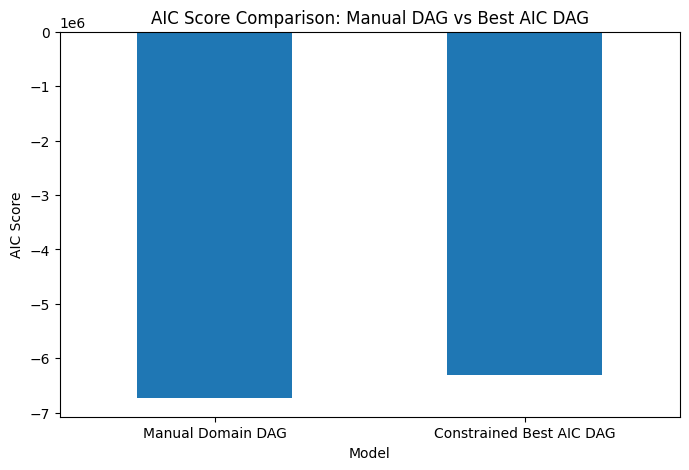

In [24]:
# ==============================
# Cell 21: Visualise AIC score comparison
# ==============================

score_compare_aic.plot(
    x="Model",
    y="AIC Score",
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("AIC Score Comparison: Manual DAG vs Best AIC DAG")
plt.ylabel("AIC Score")
plt.xticks(rotation=0)
plt.show()

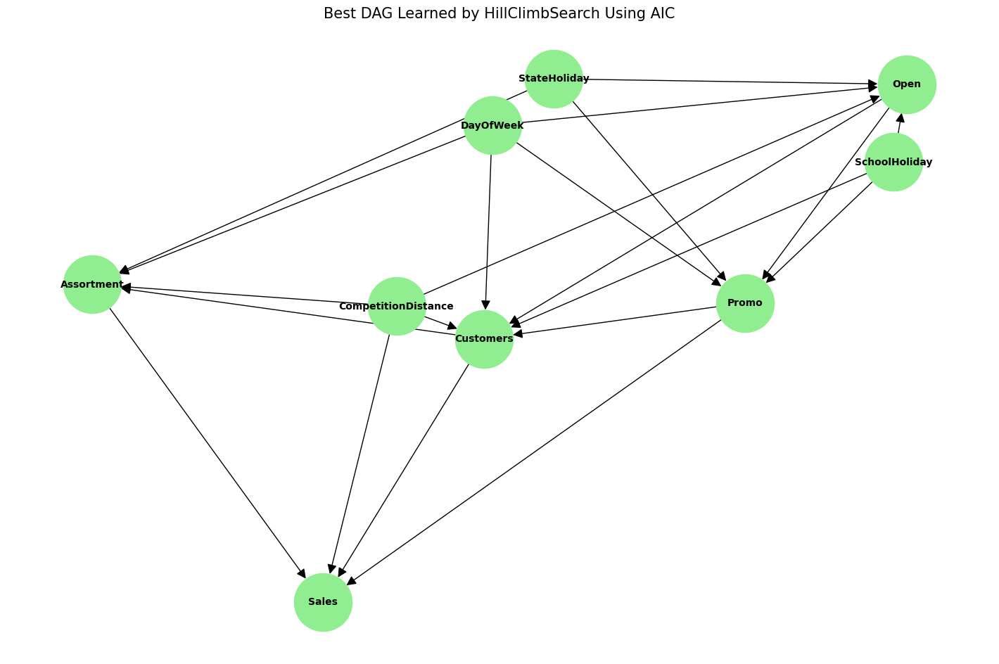

In [25]:
# ==============================
# Cell 22: Visualise Best AIC DAG
# ==============================

final_graph = nx.DiGraph(final_edges)

plt.figure(figsize=(14, 9))

pos = nx.spring_layout(final_graph, seed=42)

nx.draw(
    final_graph,
    pos,
    with_labels=True,
    node_size=3500,
    node_color="lightgreen",
    font_size=10,
    font_weight="bold",
    arrowsize=20
)

plt.title("Best DAG Learned by HillClimbSearch Using AIC", fontsize=15)
plt.show()

In [26]:
# ==============================
# Cell 23: Text summary of Best AIC DAG relationships
# ==============================

final_relationships = pd.DataFrame(
    final_edges,
    columns=["Parent Node", "Child Node"]
)

final_relationships["Relationship"] = (
    final_relationships["Parent Node"]
    + " influences "
    + final_relationships["Child Node"]
)

final_relationships

,Parent Node,Child Node,Relationship
0,Promo,Customers,Promo influences Customers
1,Promo,Sales,Promo influences Sales
2,Customers,Sales,Customers influences Sales
3,Customers,Assortment,Customers influences Assortment
4,DayOfWeek,Customers,DayOfWeek influences Customers
5,DayOfWeek,Promo,DayOfWeek influences Promo
6,DayOfWeek,Open,DayOfWeek influences Open
7,DayOfWeek,Assortment,DayOfWeek influences Assortment
8,StateHoliday,Open,StateHoliday influences Open
9,StateHoliday,Promo,StateHoliday influences Promo


In [27]:
cpds_final = {
    cpd.variable: cpd
    for cpd in final_bn.get_cpds()
}

for k, v in cpds_final.items():
    print(f"CPD Table for variable: {k}")
    display(cpd_to_pandas(v))
    print("=" * 100)

CPD Table for variable: Promo


DayOfWeek             1                                               \
Open                  0                                                
SchoolHoliday         0                             1                  
StateHoliday          0         a    b    c         0    a    b    c   
Promo=0        0.430921  0.912028  1.0  0.5  0.415385  1.0  1.0  0.5   
Promo=1        0.569079  0.087972  0.0  0.5  0.584615  0.0  0.0  0.5   

DayOfWeek                                                                   2  \
Open                  1                                                     0   
SchoolHoliday         0                            1                        0   
StateHoliday          0         a    b    c        0    a    b    c         0   
Promo=0        0.435108  0.970874  1.0  0.5  0.44662  0.5  1.0  0.5  0.473451   
Promo=1        0.564892  0.029126  0.0  0.5  0.55338  0.5  0.0  0.5  0.526549   

DayOfWeek                                                                  \
Open                                                     1                  
SchoolHoliday                   1                        0                  
StateHoliday     a    b    c    0    a    b    c         0    a    b    c   
Promo=0        0.0  0.5  0.5  0.5  1.0  0.5  0.5  0.442562  0.0  0.5  0.5   
Promo=1        1.0  0.5  0.5  0.5  0.0  0.5  0.5  0.557438  1.0  0.5  0.5   

DayOfWeek                                      3                           \
Open                                           0                            
SchoolHoliday         1                        0                        1   
StateHoliday          0    a    b    c         0         a    b    c    0   
Promo=0        0.530747  1.0  0.5  0.5  0.464115  0.059581  0.5  0.5  0.5   
Promo=1        0.469253  0.0  0.5  0.5  0.535885  0.940419  0.5  0.5  0.5   

DayOfWeek                                                                  \
Open                                 1                                      
SchoolHoliday                        0                        1             
StateHoliday     a    b    c         0    a    b    c         0    a    b   
Promo=0        1.0  0.5  1.0  0.449937  0.0  0.5  0.5  0.505784  1.0  0.5   
Promo=1        0.0  0.5  0.0  0.550063  1.0  0.5  0.5  0.494216  0.0  0.5   

DayOfWeek                  4                                               \
Open                       0                                                
SchoolHoliday              0                             1                  
StateHoliday     c         0         a    b    c         0         a    b   
Promo=0        1.0  0.427907  0.655635  0.5  0.5  0.658915  0.553668  0.5   
Promo=1        0.0  0.572093  0.344365  0.5  0.5  0.341085  0.446332  0.5   

DayOfWeek                                                                  \
Open                       1                                                
SchoolHoliday              0                             1                  
StateHoliday     c         0         a    b    c         0         a    b   
Promo=0        1.0  0.433629  0.326531  0.5  0.5  0.505399  0.419355  0.5   
Promo=1        0.0  0.566371  0.673469  0.5  0.5  0.494601  0.580645  0.5   

DayOfWeek                  5                                              \
Open                       0                                               
SchoolHoliday              0                            1                  
StateHoliday     c         0        a    b    c         0    a    b    c   
Promo=0        1.0  0.453608  0.14026  0.0  0.5  0.554054  1.0  0.0  1.0   
Promo=1        0.0  0.546392  0.85974  1.0  0.5  0.445946  0.0  1.0  0.0   

DayOfWeek                                                               6  \
Open                  1                                                 0   
SchoolHoliday         0                             1                   0   
StateHoliday          0         a    b    c         0    a    b    c    0   


CPD Table for variable: Customers


CompetitionDistance  Far                                               \
DayOfWeek              1                                                
Open                   0                        1                       
Promo                  0         1              0                   1   
SchoolHoliday          0    1    0    1         0         1         0   
Customers=High       0.0  0.0  0.0  0.0  0.133675  0.308228  0.470265   
Customers=Low        0.0  0.0  0.0  0.0  0.494849  0.343274  0.179413   
Customers=Medium     0.0  0.0  0.0  0.0  0.371477  0.348280  0.350323   
Customers=Zero       1.0  1.0  1.0  1.0  0.000000  0.000218  0.000000   

CompetitionDistance                                                    \
DayOfWeek                        2                                      
Open                             0                        1             
Promo                            0         1              0             
SchoolHoliday               1    0    1    0    1         0         1   
Customers=High       0.478013  0.0  0.0  0.0  0.0  0.116152  0.178660   
Customers=Low        0.158982  0.0  0.0  0.0  0.0  0.554347  0.501400   
Customers=Medium     0.363005  0.0  0.0  0.0  0.0  0.329439  0.319941   
Customers=Zero       0.000000  1.0  1.0  1.0  1.0  0.000062  0.000000   

CompetitionDistance                                                    \
DayOfWeek                                  3                            
Open                                       0                        1   
Promo                       1              0         1              0   
SchoolHoliday               0         1    0    1    0    1         0   
Customers=High       0.301680  0.282197  0.0  0.0  0.0  0.0  0.115154   
Customers=Low        0.307497  0.315084  0.0  0.0  0.0  0.0  0.544704   
Customers=Medium     0.390822  0.402719  0.0  0.0  0.0  0.0  0.340020   
Customers=Zero       0.000000  0.000000  1.0  1.0  1.0  1.0  0.000122   

CompetitionDistance                                                    \
DayOfWeek                                            4                  
Open                                                 0                  
Promo                                 1              0         1        
SchoolHoliday               1         0         1    0    1    0    1   
Customers=High       0.097132  0.237504  0.256915  0.0  0.0  0.0  0.0   
Customers=Low        0.586309  0.356382  0.325123  0.0  0.0  0.0  0.0   
Customers=Medium     0.316559  0.406064  0.417961  0.0  0.0  0.0  0.0   
Customers=Zero       0.000000  0.000050  0.000000  1.0  1.0  1.0  1.0   

CompetitionDistance                                                            \
DayOfWeek                                                    5                  
Open                        1                                0                  
Promo                       0                 1              0         1        
SchoolHoliday               0       1         0         1    0    1    0    1   
Customers=High       0.121075  0.1258  0.255764  0.305624  0.0  0.0  0.0  0.0   
Customers=Low        0.501464  0.4990  0.323468  0.271346  0.0  0.0  0.0  0.0   
Customers=Medium     0.377461  0.3750  0.420717  0.423030  0.0  0.0  0.0  0.0   
Customers=Zero       0.000000  0.0002  0.000051  0.000000  1.0  1.0  1.0  1.0   

CompetitionDistance                                                          \
DayOfWeek                                                      6              
Open                        1                                  0              
Promo                       0                   1              0          1   
SchoolHoliday               0         1         0         1    0    1     0   
Customers=High       0.178828  0.190631  0.298495  0.263622  0.0  0.0  0.25   
Customers=Low        0.402836  0.405660  0.261087  0.277765  0.0  0.0  0.25   
Customers=Medium     0.418336  0.403709  0.440418  0.458613  0.0  0.0  0.25   
Custom

CPD Table for variable: Sales


Assortment                  a                                          \
CompetitionDistance       Far                                           
Customers                High                 Low              Medium   
Promo                       0         1         0         1         0   
Sales=High           0.464417  0.822566  0.000028  0.011847  0.055010   
Sales=Low            0.000000  0.000000  0.556993  0.184517  0.026808   
Sales=Medium         0.535583  0.177434  0.442978  0.803637  0.918181   
Sales=Zero           0.000000  0.000000  0.000000  0.000000  0.000000   

Assortment                                                             \
CompetitionDistance                        Medium                       
Customers                     Zero           High                 Low   
Promo                       1    0    1         0         1         0   
Sales=High           0.320375  0.0  0.0  0.410685  0.721519  0.000651   
Sales=Low            0.000725  0.0  0.0  0.000819  0.000000  0.705398   
Sales=Medium         0.678901  0.0  0.0  0.588496  0.278481  0.293951   
Sales=Zero           0.000000  1.0  1.0  0.000000  0.000000  0.000000   

Assortment                                                             \
CompetitionDistance                                              Near   
Customers                        Medium           Zero           High   
Promo                       1         0         1    0    1         0   
Sales=High           0.002624  0.027231  0.137918  0.0  0.0  0.374203   
Sales=Low            0.242189  0.091460  0.011377  0.0  0.0  0.001512   
Sales=Medium         0.755186  0.881310  0.850704  0.0  0.0  0.624285   
Sales=Zero           0.000000  0.000000  0.000000  1.0  1.0  0.000000   

Assortment                                                                  \
CompetitionDistance                                                          
Customers                           Low              Medium           Zero   
Promo                       1         0         1         0         1    0   
Sales=High           0.645737  0.000030  0.004513  0.003067  0.074945  0.0   
Sales=Low            0.000000  0.818522  0.389429  0.256804  0.056474  0.0   
Sales=Medium         0.354263  0.181448  0.605971  0.740128  0.868582  0.0   
Sales=Zero           0.000000  0.000000  0.000087  0.000000  0.000000  1.0   

Assortment                   b                                             \
CompetitionDistance        Far                                              
Customers                 High         Low       Medium        Zero         
Promo                  1     0     1     0     1      0     1     0     1   
Sales=High           0.0  0.25  0.25  0.25  0.25   0.25  0.25  0.25  0.25   
Sales=Low            0.0  0.25  0.25  0.25  0.25   0.25  0.25  0.25  0.25   
Sales=Medium         0.0  0.25  0.25  0.25  0.25   0.25  0.25  0.25  0.25   
Sales=Zero           1.0  0.25  0.25  0.25  0.25   0.25  0.25  0.25  0.25   

Assortment                                                                    \
CompetitionDistance    Medium                                                  
Customers                High            Low           Medium      Zero        
Promo                       0         1    0         1      0    1    0    1   
Sales=High           0.183492  0.200000  0.0  0.000000    0.0  0.0  0.0  0.0   
Sales=Low            0.215873  0.282587  1.0  0.857143    1.0  1.0  0.0  0.0   
Sales=Medium         0.600635  0.517413  0.0  0.000000    0.0  0.0  0.0  0.0   
Sales=Zero           0.000000  0.000000  0.0  0.142857    0.0  0.0  1.0  1.0   

Assortment                                                                 \
CompetitionDistance      Near                                               
Customers                High            Low       Medium       Zero        
Promo                       0         1    0     1      0     1    0    1   
Sales=High           0.613501  0.687892  0.0  0.25    

... (8 outputs left out)

CPD Table for variable: SchoolHoliday


,Probability
SchoolHoliday=0,0.821337
SchoolHoliday=1,0.178663


CPD Table for variable: CompetitionDistance


,Probability
CompetitionDistance=Far,0.332451
CompetitionDistance=Medium,0.333445
CompetitionDistance=Near,0.334104


Local Independencies

In [28]:
# ==============================
# Cell 31: Local Independencies of Best AIC DAG
# ==============================

print("Local independencies of the Best AIC DAG:")
print(final_bn.local_independencies(list(final_bn.nodes())))

Local independencies of the Best AIC DAG:
(Assortment ⟂ Open, Promo, SchoolHoliday | CompetitionDistance, Customers, DayOfWeek, StateHoliday)
(CompetitionDistance ⟂ DayOfWeek, SchoolHoliday, StateHoliday)
(Customers ⟂ StateHoliday | CompetitionDistance, DayOfWeek, Open, Promo, SchoolHoliday)
(DayOfWeek ⟂ CompetitionDistance, SchoolHoliday, StateHoliday)
(Promo ⟂ CompetitionDistance | DayOfWeek, Open, SchoolHoliday, StateHoliday)
(Sales ⟂ DayOfWeek, Open, SchoolHoliday, StateHoliday | Assortment, CompetitionDistance, Customers, Promo)
(SchoolHoliday ⟂ CompetitionDistance, DayOfWeek, StateHoliday)
(StateHoliday ⟂ CompetitionDistance, DayOfWeek, SchoolHoliday)


In [29]:
print("Local independencies of Sales:")
print(final_bn.local_independencies("Sales"))

Local independencies of Sales:
(Sales ⟂ DayOfWeek, Open, SchoolHoliday, StateHoliday | Assortment, CompetitionDistance, Customers, Promo)


列出了每个节点的 active trail nodes，用于展示在没有额外证据条件下，哪些变量仍然与该节点存在概率连接

In [30]:
# ==============================
# Active trails for all nodes - full display
# ==============================

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

all_active_trails = {}

for node in final_bn.nodes():
    all_active_trails[node] = sorted(list(final_bn.active_trail_nodes(node)[node]))

active_trails_df = pd.DataFrame({
    "Node": list(all_active_trails.keys()),
    "Active Trail Nodes": [", ".join(nodes) for nodes in all_active_trails.values()]
})

active_trails_df

,Node,Active Trail Nodes
0,Promo,"Assortment, CompetitionDistance, Customers, DayOfWeek, Open, Promo, Sales, SchoolHoliday, StateHoliday"
1,Customers,"Assortment, CompetitionDistance, Customers, DayOfWeek, Open, Promo, Sales, SchoolHoliday, StateHoliday"
2,Sales,"Assortment, CompetitionDistance, Customers, DayOfWeek, Open, Promo, Sales, SchoolHoliday, StateHoliday"
3,Assortment,"Assortment, CompetitionDistance, Customers, DayOfWeek, Open, Promo, Sales, SchoolHoliday, StateHoliday"
4,DayOfWeek,"Assortment, Customers, DayOfWeek, Open, Promo, Sales"
5,Open,"Assortment, CompetitionDistance, Customers, DayOfWeek, Open, Promo, Sales, SchoolHoliday, StateHoliday"
6,StateHoliday,"Assortment, Customers, Open, Promo, Sales, StateHoliday"
7,SchoolHoliday,"Assortment, Customers, Open, Promo, Sales, SchoolHoliday"
8,CompetitionDistance,"Assortment, CompetitionDistance, Customers, Open, Promo, Sales"


v-structure activation

In [31]:
# ==============================
# Detect V-structures in the Best AIC DAG
# ==============================

def find_v_structures(edges):
    graph = nx.DiGraph(edges)
    v_structures = []
    
    for child in graph.nodes():
        parents = list(graph.predecessors(child))
        
        if len(parents) >= 2:
            for i in range(len(parents)):
                for j in range(i + 1, len(parents)):
                    p1 = parents[i]
                    p2 = parents[j]
                    
                    # A v-structure requires:
                    # p1 -> child <- p2
                    # and p1, p2 are not directly connected
                    if not graph.has_edge(p1, p2) and not graph.has_edge(p2, p1):
                        v_structures.append((p1, child, p2))
    
    return v_structures

v_structures = find_v_structures(final_edges)

print("Detected V-structures A → C ← B:")

for p1, collider, p2 in v_structures:
    print(f"{p1} → {collider} ← {p2}")

Detected V-structures A → C ← B:
DayOfWeek → Promo ← StateHoliday
DayOfWeek → Promo ← SchoolHoliday
StateHoliday → Promo ← SchoolHoliday
Promo → Customers ← CompetitionDistance
DayOfWeek → Customers ← SchoolHoliday
DayOfWeek → Customers ← CompetitionDistance
SchoolHoliday → Customers ← CompetitionDistance
Promo → Sales ← CompetitionDistance
Promo → Sales ← Assortment
Customers → Assortment ← StateHoliday
DayOfWeek → Assortment ← StateHoliday
DayOfWeek → Assortment ← CompetitionDistance
StateHoliday → Assortment ← CompetitionDistance
DayOfWeek → Open ← StateHoliday
DayOfWeek → Open ← SchoolHoliday
DayOfWeek → Open ← CompetitionDistance
StateHoliday → Open ← SchoolHoliday
StateHoliday → Open ← CompetitionDistance
SchoolHoliday → Open ← CompetitionDistance


In [32]:
# ==============================
# V-structure activation: choose one example
# ==============================

parent_1 = "Promo"
collider = "Sales"
parent_2 = "Assortment"

print("Selected V-structure:")
print(f"{parent_1} → {collider} ← {parent_2}")

Selected V-structure:
Promo → Sales ← Assortment


未观测 collider 时：

$$
V_{\text{without observing Sales}}
=
\sqrt{
\frac{
\chi^2(\text{Promo}, \text{Assortment})
}{
n \cdot \min(r-1, c-1)
}
}
$$

观测 collider 后，例如只看 \(Sales = High\) 的子数据：

$$
V_{\text{after observing Sales=High}}
=
\sqrt{
\frac{
\chi^2(\text{Promo}, \text{Assortment} \mid \text{Sales}=High)
}{
n_{\text{Sales}=High} \cdot \min(r-1, c-1)
}
}
$$

其中，卡方统计量为：

$$
\chi^2
=
\sum_{i=1}^{r}
\sum_{j=1}^{c}
\frac{
(O_{ij} - E_{ij})^2
}{
E_{ij}
}
$$

期望频数为：

$$
E_{ij}
=
\frac{
(\text{row total}_i)(\text{column total}_j)
}{
n
}
$$

| 符号               | 含义              |
| ---------------- | --------------- |
| (V)              | Cramér's V 关联强度 |
| (\chi^2)         | 卡方检验统计量         |
| (n)              | 样本总数            |
| (r)              | 交叉表的行数          |
| (c)              | 交叉表的列数          |
| (\min(r-1, c-1)) | 对表格维度做标准化       |


In [33]:
# ==============================
# Define Cramér's V for categorical association
# ==============================

from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

def cramers_v(x, y):
    """
    Calculate Cramér's V for two categorical variables.
    The value ranges from 0 to 1.
    0 means no association; 1 means strong association.
    """
    confusion_matrix = pd.crosstab(x, y)
    
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    
    if n == 0:
        return np.nan
    
    r, k = confusion_matrix.shape
    
    denominator = n * (min(r - 1, k - 1))
    
    if denominator == 0:
        return np.nan
    
    return np.sqrt(chi2 / denominator)

In [34]:
# ==============================
# Association between two parent nodes without observing collider
# ==============================

association_without_observing_collider = cramers_v(
    bn_data[parent_1],
    bn_data[parent_2]
)

print(f"Cramér's V between {parent_1} and {parent_2} without observing {collider}:")
print(association_without_observing_collider)

Cramér's V between Promo and Assortment without observing Sales:
0.00029092883604199646


In [35]:
# ==============================
# Association between parent nodes after observing collider states
# ==============================

collider_states = bn_data[collider].cat.categories

v_structure_activation_results = []

for state in collider_states:
    subset = bn_data[bn_data[collider] == state]
    
    association_after_observing_collider = cramers_v(
        subset[parent_1],
        subset[parent_2]
    )
    
    v_structure_activation_results.append({
        "V-structure": f"{parent_1} → {collider} ← {parent_2}",
        "Observed Collider": f"{collider} = {state}",
        "Sample Size": len(subset),
        "Cramér's V without observing collider": association_without_observing_collider,
        "Cramér's V after observing collider": association_after_observing_collider,
        "Change": association_after_observing_collider - association_without_observing_collider
    })

v_structure_activation_df = pd.DataFrame(v_structure_activation_results)

v_structure_activation_df

,V-structure,Observed Collider,Sample Size,Cramér's V without observing collider,Cramér's V after observing collider,Change
0,Promo → Sales ← Assortment,Sales = High,216842,0.000291,0.101382,0.101091
1,Promo → Sales ← Assortment,Sales = Low,158607,0.000291,0.061767,0.061476
2,Promo → Sales ← Assortment,Sales = Medium,466703,0.000291,0.065215,0.064924
3,Promo → Sales ← Assortment,Sales = Zero,172415,0.000291,0.030438,0.030147


block之后仍流通

In [36]:
# ==============================
# Blocked information flow to Sales after observing Customers
# ==============================

target_node = "Sales"
evidence_nodes = ["Customers"]

blocked_flow_results = []

for node in final_bn.nodes():
    if node == target_node:
        continue
    
    connected_without_evidence = final_bn.is_dconnected(
        node,
        target_node
    )
    
    connected_with_evidence = final_bn.is_dconnected(
        node,
        target_node,
        observed=evidence_nodes
    )
    
    blocked_flow_results.append({
        "Node": node,
        "Target": target_node,
        "Evidence": ", ".join(evidence_nodes),
        "D-connected without evidence": connected_without_evidence,
        "D-connected after evidence": connected_with_evidence,
        "Blocked by evidence?": connected_without_evidence and not connected_with_evidence
    })

blocked_flow_df = pd.DataFrame(blocked_flow_results)

blocked_flow_df

,Node,Target,Evidence,D-connected without evidence,D-connected after evidence,Blocked by evidence?
0,Promo,Sales,Customers,True,True,False
1,Customers,Sales,Customers,True,False,True
2,Assortment,Sales,Customers,True,True,False
3,DayOfWeek,Sales,Customers,True,True,False
4,Open,Sales,Customers,True,True,False
5,StateHoliday,Sales,Customers,True,True,False
6,SchoolHoliday,Sales,Customers,True,True,False
7,CompetitionDistance,Sales,Customers,True,True,False


In [37]:
# ==============================
# Nodes still connected to Sales after observing evidence
# ==============================

still_connected_df = blocked_flow_df[
    blocked_flow_df["D-connected after evidence"] == True
].copy()

still_connected_df

,Node,Target,Evidence,D-connected without evidence,D-connected after evidence,Blocked by evidence?
0,Promo,Sales,Customers,True,True,False
2,Assortment,Sales,Customers,True,True,False
3,DayOfWeek,Sales,Customers,True,True,False
4,Open,Sales,Customers,True,True,False
5,StateHoliday,Sales,Customers,True,True,False
6,SchoolHoliday,Sales,Customers,True,True,False
7,CompetitionDistance,Sales,Customers,True,True,False


In [38]:
# ==============================
# Select one medium-length unblocked directed path directly from blocked_flow_df
# ==============================

target_node = "Sales"
evidence_nodes = ["Customers"]


# 1. Select nodes that are still d-connected to Sales after observing evidence
still_connected_nodes = blocked_flow_df[
    blocked_flow_df["D-connected after evidence"] == True
]["Node"].tolist()

print("Nodes still connected to Sales after observing evidence:")
print(still_connected_nodes)

# 2. Find directed paths from these nodes to Sales
path_candidates = []

for source_node_candidate in still_connected_nodes:
    all_directed_paths = list(
        nx.all_simple_paths(
            final_graph,
            source=source_node_candidate,
            target=target_node,
            cutoff=6
        )
    )
    
    for path in all_directed_paths:
        intermediate_nodes = path[1:-1]
        
        # Keep paths that do not pass through evidence nodes as intermediate nodes
        passes_through_evidence = any(
            node in evidence_nodes
            for node in intermediate_nodes
        )
        
        if not passes_through_evidence:
            path_candidates.append({
                "Source Node": source_node_candidate,
                "Directed Path": " → ".join(path),
                "Path List": path,
                "Path Length": len(path)
            })

path_candidates_df = pd.DataFrame(path_candidates)

print("\nCandidate unblocked directed paths:")
display(path_candidates_df)

# 3. Prefer medium-length paths: exactly 4 nodes
medium_paths_df = path_candidates_df[
    path_candidates_df["Path Length"] == 4
].copy()

# 4. If length-4 paths exist, choose the first one.
# Otherwise, choose the shortest available path.
if len(medium_paths_df) > 0:
    selected_row = medium_paths_df.iloc[0]
else:
    selected_row = path_candidates_df.sort_values("Path Length").iloc[0]

selected_path_text = selected_row["Directed Path"]
selected_path = selected_row["Path List"]
source_node = selected_row["Source Node"]

print("\nSelected source node:", source_node)
print("Selected unblocked directed path:")
print(selected_path_text)
print("Path length:", len(selected_path))

Nodes still connected to Sales after observing evidence:
['Promo', 'Assortment', 'DayOfWeek', 'Open', 'StateHoliday', 'SchoolHoliday', 'CompetitionDistance']

Candidate unblocked directed paths:


,Source Node,Directed Path,Path List,Path Length
0,Promo,Promo → Sales,"[Promo, Sales]",2
1,Assortment,Assortment → Sales,"[Assortment, Sales]",2
2,DayOfWeek,DayOfWeek → Promo → Sales,"[DayOfWeek, Promo, Sales]",3
3,DayOfWeek,DayOfWeek → Open → Promo → Sales,"[DayOfWeek, Open, Promo, Sales]",4
4,DayOfWeek,DayOfWeek → Assortment → Sales,"[DayOfWeek, Assortment, Sales]",3
5,Open,Open → Promo → Sales,"[Open, Promo, Sales]",3
6,StateHoliday,StateHoliday → Open → Promo → Sales,"[StateHoliday, Open, Promo, Sales]",4
7,StateHoliday,StateHoliday → Promo → Sales,"[StateHoliday, Promo, Sales]",3
8,StateHoliday,StateHoliday → Assortment → Sales,"[StateHoliday, Assortment, Sales]",3
9,SchoolHoliday,SchoolHoliday → Open → Promo → Sales,"[SchoolHoliday, Open, Promo, Sales]",4



Selected source node: DayOfWeek
Selected unblocked directed path:
DayOfWeek → Open → Promo → Sales
Path length: 4


In [39]:
# ==============================
# Visualise Best AIC DAG with selected unblocked directed path
# ==============================

def plot_final_dag_with_selected_path(
    graph,
    selected_path,
    query_node,
    evidence_nodes=None,
    title="The Best AIC DAG with Selected Unblocked Path"
):
    evidence_nodes = evidence_nodes or []
    
    path_nodes = set(selected_path)
    path_edges = set()
    
    for i in range(len(selected_path) - 1):
        path_edges.add((selected_path[i], selected_path[i + 1]))
    
    node_colors = []
    
    for node in graph.nodes():
        if node == query_node:
            node_colors.append("orange")
        elif node in evidence_nodes:
            node_colors.append("red")
        elif node in path_nodes:
            node_colors.append("lightgreen")
        else:
            node_colors.append("lightblue")
    
    plt.figure(figsize=(14, 9))
    
    pos = nx.spring_layout(graph, seed=42)
    
    nx.draw_networkx_nodes(
        graph,
        pos,
        node_color=node_colors,
        node_size=2800,
        edgecolors="black",
        linewidths=1
    )
    
    normal_edges = [
        edge for edge in graph.edges()
        if edge not in path_edges
    ]
    
    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=normal_edges,
        arrows=True,
        arrowstyle="-|>",
        arrowsize=24,
        width=1.5,
        alpha=0.35,
        min_source_margin=18,
        min_target_margin=18
    )
    
    nx.draw_networkx_edges(
        graph,
        pos,
        edgelist=list(path_edges),
        arrows=True,
        arrowstyle="-|>",
        arrowsize=32,
        width=4,
        alpha=0.95,
        min_source_margin=20,
        min_target_margin=20
    )
    
    nx.draw_networkx_labels(
        graph,
        pos,
        font_size=10,
        font_weight="bold"
    )
    
    import matplotlib.patches as mpatches
    
    legend_items = [
        mpatches.Patch(color="orange", label="Query node: Sales"),
        mpatches.Patch(color="red", label="Evidence / blocked node: Customers"),
        mpatches.Patch(color="lightgreen", label="Selected unblocked directed path"),
        mpatches.Patch(color="lightblue", label="Other node")
    ]
    
    plt.legend(handles=legend_items, loc="best")
    plt.title(title, fontsize=15)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

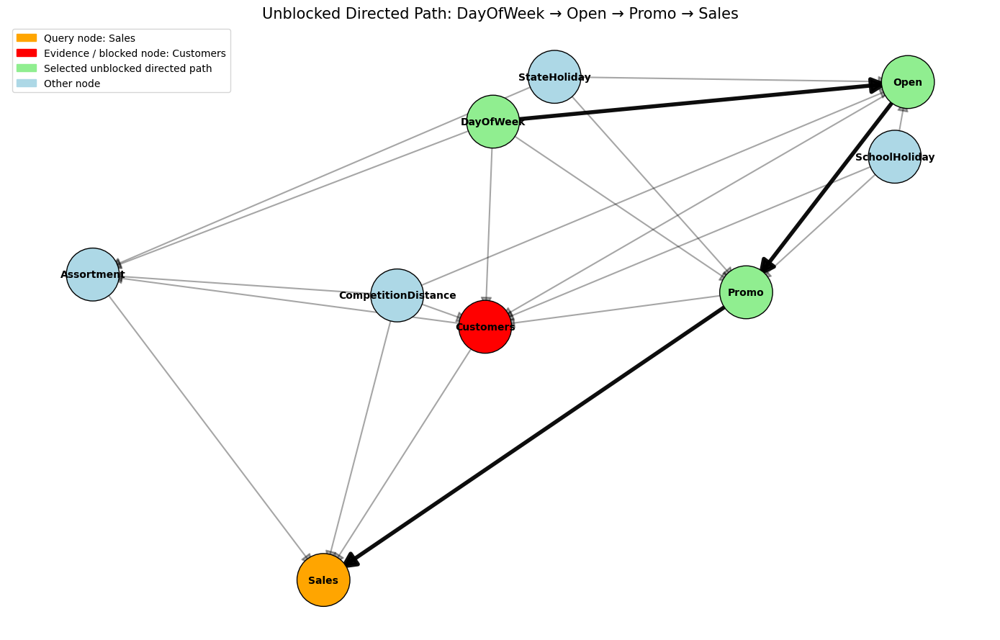

In [40]:
plot_final_dag_with_selected_path(
    graph=final_graph,
    selected_path=selected_path,
    query_node="Sales",
    evidence_nodes=evidence_nodes,
    title=f"Unblocked Directed Path: {selected_path_text}"
)

Belief Propagation = 基于  Clique Tree 的团树推理

In [41]:
# ==============================
# Manual Junction Tree Query Function
# ==============================

from pgmpy.factors.discrete import DiscreteFactor
import numpy as np
import networkx as nx

def manual_junction_tree_query(bn, query_variable, evidence_dict=None):
    evidence_dict = evidence_dict or {}

    junction_tree = bn.to_junction_tree()
    jt_graph = nx.Graph(junction_tree.edges())

    # 1. Collect state names and cardinalities
    state_names = {}
    cardinality = {}

    for cpd in bn.get_cpds():
        for var, states in cpd.state_names.items():
            state_names[var] = states
            cardinality[var] = len(states)

    # 2. Create identity clique potentials
    clique_potentials = {}

    for clique in junction_tree.nodes():
        clique_vars = list(clique)
        clique_cards = [cardinality[var] for var in clique_vars]
        clique_state_names = {var: state_names[var] for var in clique_vars}

        values = np.ones(np.prod(clique_cards))

        clique_potentials[clique] = DiscreteFactor(
            variables=clique_vars,
            cardinality=clique_cards,
            values=values,
            state_names=clique_state_names
        )

    # 3. Helper functions
    def factor_product(factor_1, factor_2):
        result = factor_1.copy()
        result.product(factor_2, inplace=True)
        return result

    def factor_marginalize(factor, variables_to_remove):
        result = factor.copy()
        if len(variables_to_remove) > 0:
            result.marginalize(variables_to_remove, inplace=True)
        return result

    def factor_reduce(factor, evidence):
        result = factor.copy()

        reduce_list = []
        for var, value in evidence.items():
            if var in result.scope():
                reduce_list.append((var, value))

        if len(reduce_list) > 0:
            result.reduce(reduce_list, inplace=True)

        return result

    def normalize_factor(factor):
        result = factor.copy()
        total = result.values.sum()

        if total != 0:
            result.values = result.values / total

        return result

    # 4. Assign CPDs to clique potentials
    for cpd in bn.get_cpds():
        factor = cpd.to_factor()
        factor_scope = set(factor.scope())

        assigned = False

        for clique in junction_tree.nodes():
            if factor_scope.issubset(set(clique)):
                clique_potentials[clique] = factor_product(
                    clique_potentials[clique],
                    factor
                )
                assigned = True
                break

        if not assigned:
            raise ValueError(f"CPD factor {factor_scope} was not assigned to any clique.")

    # 5. Apply evidence
    evidenced_clique_potentials = {}

    for clique, potential in clique_potentials.items():
        evidenced_clique_potentials[clique] = factor_reduce(
            potential,
            evidence_dict
        )

    # 6. Message passing
    message_cache = {}

    def compute_message(sender, receiver):
        key = (sender, receiver)

        if key in message_cache:
            return message_cache[key]

        message_factor = evidenced_clique_potentials[sender].copy()

        for neighbor in jt_graph.neighbors(sender):
            if neighbor != receiver:
                incoming_message = compute_message(neighbor, sender)
                message_factor = factor_product(message_factor, incoming_message)

        separator = set(sender).intersection(set(receiver))

        variables_to_sum_out = [
            var for var in message_factor.scope()
            if var not in separator
        ]

        message_factor = factor_marginalize(
            message_factor,
            variables_to_sum_out
        )

        message_factor = normalize_factor(message_factor)

        message_cache[key] = message_factor

        return message_factor

    # 7. Choose query clique
    query_clique = None

    for clique in junction_tree.nodes():
        if query_variable in clique:
            query_clique = clique
            break

    if query_clique is None:
        raise ValueError(f"No clique contains query variable {query_variable}.")

    # 8. Compute calibrated belief
    query_belief = evidenced_clique_potentials[query_clique].copy()

    for neighbor in jt_graph.neighbors(query_clique):
        incoming_message = compute_message(neighbor, query_clique)
        query_belief = factor_product(query_belief, incoming_message)

    # 9. Marginalise to query variable
    variables_to_remove = [
        var for var in query_belief.scope()
        if var != query_variable
    ]

    result = factor_marginalize(
        query_belief,
        variables_to_remove
    )

    result = normalize_factor(result)

    return result


In [42]:
# ==============================
# Helper function: convert query result to ordered DataFrame
# ==============================

def query_result_to_ordered_df(query_result, variable_name):
    states = list(query_result.state_names[variable_name])
    probs = query_result.values
    
    result_df = pd.DataFrame({
        variable_name: states,
        "Probability": probs
    })
    
    order_dict = {
        "Sales": ["High", "Medium", "Low", "Zero"],
        "Customers": ["High", "Medium", "Low", "Zero"],
        "CompetitionDistance": ["Near", "Medium", "Far"],
        "Promo": [0, 1],
        "Open": [0, 1],
        "SchoolHoliday": [0, 1],
        "DayOfWeek": [1, 2, 3, 4, 5, 6, 7],
        "StateHoliday": ["0", "a", "b", "c"],
        "Assortment": ["a", "b", "c"]
    }
    
    if variable_name in order_dict:
        order = [
            state for state in order_dict[variable_name]
            if state in result_df[variable_name].tolist()
        ]
    else:
        order = states
    
    result_df[variable_name] = pd.Categorical(
        result_df[variable_name],
        categories=order,
        ordered=True
    )
    
    result_df = result_df.sort_values(variable_name).reset_index(drop=True)
    result_df["Probability"] = result_df["Probability"].round(4)
    
    return result_df

In [43]:
# ==============================
# Generic query function: compute P(query_variable | evidence)
# ==============================

def query_posterior(query_variable, evidence_dict=None):
    """
    Compute posterior probability distribution:
    P(query_variable | evidence)

    This function supports:
    1. Forward query: causes/evidence -> Sales
    2. Diagnostic query: Sales -> possible causes
    3. Mixed query: Sales + other evidence -> another variable
    """
    
    evidence_dict = evidence_dict or {}
    
    if query_variable in evidence_dict:
        raise ValueError(
            f"The query variable '{query_variable}' cannot also appear in evidence."
        )
    
    posterior = manual_junction_tree_query(
        bn=final_bn,
        query_variable=query_variable,
        evidence_dict=evidence_dict
    )
    
    result_df = query_result_to_ordered_df(
        posterior,
        query_variable
    )
    
    return posterior, result_df

In [44]:
# ==============================
# Query Sales posterior with timing and inference trace
# ==============================

import time
import networkx as nx

def query_sales_posterior_with_trace(evidence_dict=None):
    """
    Compute P(Sales | evidence), record execution time,
    and show the Junction Tree message-passing trace.
    """
    
    evidence_dict = evidence_dict or {}
    
    start_time = time.perf_counter()
    
    posterior = manual_junction_tree_query(
        bn=final_bn,
        query_variable="Sales",
        evidence_dict=evidence_dict
    )
    
    end_time = time.perf_counter()
    
    result_df = query_result_to_ordered_df(
        posterior,
        "Sales"
    )
    
    elapsed_time = end_time - start_time
    
    # Build Junction Tree again for trace display
    junction_tree = final_bn.to_junction_tree()
    jt_graph = nx.Graph(junction_tree.edges())
    
    # Find query clique containing Sales
    query_clique = None
    for clique in junction_tree.nodes():
        if "Sales" in clique:
            query_clique = clique
            break
    
    # Find evidence cliques
    evidence_cliques = {}
    
    for evidence_var in evidence_dict.keys():
        for clique in junction_tree.nodes():
            if evidence_var in clique:
                evidence_cliques[evidence_var] = clique
                break
    
    # Find paths from evidence cliques to query clique
    message_paths = {}
    
    for evidence_var, evidence_clique in evidence_cliques.items():
        if evidence_clique == query_clique:
            path = [evidence_clique]
        else:
            path = nx.shortest_path(
                jt_graph,
                source=evidence_clique,
                target=query_clique
            )
        
        message_paths[evidence_var] = path
    
    trace_info = {
        "Evidence": evidence_dict,
        "Query Variable": "Sales",
        "Query Clique": query_clique,
        "Evidence Cliques": evidence_cliques,
        "Message Paths": message_paths,
        "Execution Time (seconds)": elapsed_time
    }
    
    return posterior, result_df, trace_info

In [45]:
# ==============================
# Helper function: print query trace
# ==============================

def print_query_trace(trace_info):
    print("Query variable:")
    print(trace_info["Query Variable"])
    
    print("\nSelected evidence:")
    for var, value in trace_info["Evidence"].items():
        print(f"- {var} = {value}")
    
    print("\nQuery clique containing Sales:")
    print(trace_info["Query Clique"])
    
    print("\nEvidence cliques:")
    for var, clique in trace_info["Evidence Cliques"].items():
        print(f"- {var}: {clique}")
    
    print("\nMessage paths from evidence cliques to query clique:")
    for var, path in trace_info["Message Paths"].items():
        path_text = " -> ".join([str(clique) for clique in path])
        print(f"- {var}: {path_text}")
    
    print("\nExecution time:")
    print(f"{trace_info['Execution Time (seconds)']:.6f} seconds")

P(Sales | Open=1, Promo=1, Customers=High)

In [46]:
# ==============================
# Efficiency Example 1: simple query
# ==============================

query_example_1 = {
    "Promo": 1
}

posterior_1, result_df_1, trace_1 = query_sales_posterior_with_trace(
    evidence_dict=query_example_1
)

print("Example 1: P(Sales | Promo=1)")
display(result_df_1)
print_query_trace(trace_1)

Example 1: P(Sales | Promo=1)


,Sales,Probability
0,High,0.3954
1,Medium,0.5183
2,Low,0.0575
3,Zero,0.0288


Query variable:
Sales

Selected evidence:
- Promo = 1

Query clique containing Sales:
('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Evidence cliques:
- Promo: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Message paths from evidence cliques to query clique:
- Promo: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Execution time:
0.004574 seconds


In [47]:
# ==============================
# Efficiency Example 2: medium-complexity query
# ==============================

query_example_2 = {
    "Open": 1,
    "Promo": 1,
    "Customers": "High"
}

posterior_2, result_df_2, trace_2 = query_sales_posterior_with_trace(
    evidence_dict=query_example_2
)

print("Example 2: P(Sales | Open=1, Promo=1, Customers=High)")
display(result_df_2)
print_query_trace(trace_2)

Example 2: P(Sales | Open=1, Promo=1, Customers=High)


,Sales,Probability
0,High,0.7440
1,Medium,0.2532
2,Low,0.0027
3,Zero,0.0001


Query variable:
Sales

Selected evidence:
- Open = 1
- Promo = 1
- Customers = High

Query clique containing Sales:
('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Evidence cliques:
- Open: ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'SchoolHoliday', 'Open')
- Promo: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')
- Customers: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Message paths from evidence cliques to query clique:
- Open: ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'SchoolHoliday', 'Open') -> ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'Assortment') -> ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')
- Promo: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')
- Customers: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Execution time:
0.003242 seconds


In [48]:
# ==============================
# Efficiency Example 3: complex query
# ==============================

query_example_3 = {
    "Open": 1,
    "Promo": 1,
    "Customers": "High",
    "DayOfWeek": 5,
    "StateHoliday": "0",
    "SchoolHoliday": 0,
    "CompetitionDistance": "Near",
    "Assortment": "c"
}

posterior_3, result_df_3, trace_3 = query_sales_posterior_with_trace(
    evidence_dict=query_example_3
)

print("Example 3: P(Sales | multiple evidence variables)")
display(result_df_3)
print_query_trace(trace_3)

Example 3: P(Sales | multiple evidence variables)


,Sales,Probability
0,High,0.7314
1,Medium,0.2686
2,Low,0.0000
3,Zero,0.0000


Query variable:
Sales

Selected evidence:
- Open = 1
- Promo = 1
- Customers = High
- DayOfWeek = 5
- StateHoliday = 0
- SchoolHoliday = 0
- CompetitionDistance = Near
- Assortment = c

Query clique containing Sales:
('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')

Evidence cliques:
- Open: ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'SchoolHoliday', 'Open')
- Promo: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')
- Customers: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')
- DayOfWeek: ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'Assortment')
- StateHoliday: ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'Assortment')
- SchoolHoliday: ('Customers', 'CompetitionDistance', 'Promo', 'DayOfWeek', 'StateHoliday', 'SchoolHoliday', 'Open')
- CompetitionDistance: ('Customers', 'CompetitionDistance', 'Promo', 'Sales', 'Assortment')
- Assortmen

In [49]:
# ==============================
# Query efficiency summary
# ==============================

query_efficiency_summary = pd.DataFrame({
    "Query": [
        "P(Sales | Promo=1)",
        "P(Sales | Open=1, Promo=1, Customers=High)",
        "P(Sales | multiple evidence variables)"
    ],
    "Number of Evidence Variables": [
        len(query_example_1),
        len(query_example_2),
        len(query_example_3)
    ],
    "Execution Time (seconds)": [
        trace_1["Execution Time (seconds)"],
        trace_2["Execution Time (seconds)"],
        trace_3["Execution Time (seconds)"]
    ]
})

query_efficiency_summary["Execution Time (seconds)"] = (
    query_efficiency_summary["Execution Time (seconds)"].round(6)
)

query_efficiency_summary

,Query,Number of Evidence Variables,Execution Time (seconds)
0,P(Sales | Promo=1),1,0.004574
1,"P(Sales | Open=1, Promo=1, Customers=High)",3,0.003242
2,P(Sales | multiple evidence variables),8,0.003443


Diagnostic query

In [50]:
# ==============================
# Example 4: Diagnostic query
# P(Promo | Sales = High)
# ==============================

query_example_4_evidence = {
    "Sales": "High"
}

query4_posterior, query4_result_df = query_posterior(
    query_variable="Promo",
    evidence_dict=query_example_4_evidence
)

print("Example 4: Diagnostic query")
print("P(Promo | Sales = High)")

display(query4_result_df)

Example 4: Diagnostic query
P(Promo | Sales = High)


,Promo,Probability
0,0,0.2879
1,1,0.7121


Mixed query

In [51]:
# ==============================
# Example 5: Mixed query
# P(Promo | Sales = High, Open = 1, Customers = High)
# ==============================

query_example_5_evidence = {
    "Sales": "High",
    "Open": 1,
    "Customers": "High"
}

query5_posterior, query5_result_df = query_posterior(
    query_variable="Promo",
    evidence_dict=query_example_5_evidence
)

print("Example 5: Mixed query")
print("P(Promo | Sales = High, Open = 1, Customers = High)")

display(query5_result_df)

Example 5: Mixed query
P(Promo | Sales = High, Open = 1, Customers = High)


,Promo,Probability
0,0,0.3095
1,1,0.6905


Inner

评估

In [52]:
# ==============================
# Evaluation setup: row-by-row classification using manual Junction Tree
# ==============================

from tqdm import tqdm
import pandas as pd
import numpy as np

target_variable = "Sales"

evidence_variables = [
    "Open",
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "CompetitionDistance",
    "Assortment"
]

evaluation_data = bn_data[evidence_variables + [target_variable]].copy()

print("Target variable:", target_variable)
print("Evidence variables:", evidence_variables)
print("Evaluation data shape:", evaluation_data.shape)

Target variable: Sales
Evidence variables: ['Open', 'Promo', 'Customers', 'DayOfWeek', 'StateHoliday', 'SchoolHoliday', 'CompetitionDistance', 'Assortment']
Evaluation data shape: (1014567, 9)


In [53]:
# ==============================
# Function: Row-by-row evaluation using manual Junction Tree
# ==============================

from tqdm import tqdm

def evaluate_with_manual_junction_tree(
    data,
    bn,
    target_variable,
    evidence_variables,
    desc="Evaluating rows with manual Junction Tree"
):
    """
    Row-by-row classification evaluation using manual Junction Tree inference.

    For each row:
    1. Use evidence variables as evidence.
    2. Query P(target_variable | evidence).
    3. Select the state with the highest posterior probability as prediction.
    4. Compare prediction with the true target label.
    5. Return evaluated dataframe and accuracy summary.
    """
    
    evaluation_data = data[evidence_variables + [target_variable]].copy()
    
    predicted_labels = []
    prediction_probabilities = []

    for idx, row in tqdm(
        evaluation_data.iterrows(),
        total=len(evaluation_data),
        desc=desc
    ):
        evidence = {
            var: row[var]
            for var in evidence_variables
        }
        
        posterior = manual_junction_tree_query(
            bn=bn,
            query_variable=target_variable,
            evidence_dict=evidence
        )
        
        states = list(posterior.state_names[target_variable])
        probabilities = posterior.values
        
        max_index = int(np.argmax(probabilities))
        predicted_label = states[max_index]
        max_probability = float(probabilities[max_index])
        
        predicted_labels.append(predicted_label)
        prediction_probabilities.append(max_probability)
    
    evaluation_data["Predicted Sales"] = predicted_labels
    evaluation_data["Prediction Probability"] = prediction_probabilities
    
    evaluation_data["Correct Prediction"] = (
        evaluation_data["Predicted Sales"] == evaluation_data[target_variable]
    )
    
    correct_predictions = evaluation_data["Correct Prediction"].sum()
    total_samples = len(evaluation_data)
    accuracy = correct_predictions / total_samples
    
    summary = pd.DataFrame({
        "Metric": [
            "Correct predictions",
            "Total samples",
            "Accuracy"
        ],
        "Value": [
            int(correct_predictions),
            int(total_samples),
            round(accuracy, 4)
        ]
    })
    
    return evaluation_data, summary

$$
\text{Accuracy}
=
\frac{
\text{Number of correct predictions}
}{
\text{Total number of samples}
}
$$

In [ ]:
# ==============================
# Train evaluation using manual Junction Tree
# ==============================

target_variable = "Sales"

evidence_variables = [
    "Open",
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "CompetitionDistance",
    "Assortment"
]

train_evaluation_data, train_evaluation_summary = evaluate_with_manual_junction_tree(
    data=bn_data,
    bn=final_bn,
    target_variable=target_variable,
    evidence_variables=evidence_variables,
    desc="Evaluating train data with manual Junction Tree"
)

train_evaluation_summary

Evaluating train data with manual Junction Tree:  46%|████▌     | 466846/1014567 [34:03<33:57, 268.86it/s]  

test

In [ ]:
# ==============================
# test.csv for Bayesian Network evaluation
# Steps:
# test.csv
# → merge store.csv
# → select columns
# → drop missing values
# → apply training bin_settings
# → get test_bn_data
# ==============================
# 1. merge store.csv
test = pd.read_excel("data/test_data.xlsx")

print("Original test.csv shape:", test.shape)


test_df = test.merge(
    store[["Store", "Assortment", "CompetitionDistance"]],
    on="Store",
    how="left"
)

# Keep StateHoliday format consistent with training data
test_df["StateHoliday"] = test_df["StateHoliday"].astype(str)

print("Merged test_df shape:", test_df.shape)
display(test_df.head())


# 2. select columns
target_variable = "Sales"

evidence_variables = [
    "Open",
    "Promo",
    "Customers",
    "DayOfWeek",
    "StateHoliday",
    "SchoolHoliday",
    "CompetitionDistance",
    "Assortment"
]

test_selected_cols = evidence_variables + [target_variable]

test_bn_raw = test_df[test_selected_cols].copy()



# 3. Drop missing values
test_bn_raw = test_bn_raw.dropna().copy()

print("\nShape after dropping missing values:", test_bn_raw.shape)

# 4. Apply training bin_settings

test_bn_data = test_bn_raw.copy()


def apply_zero_plus_qcut_from_training(series, training_bins, labels_nonzero):
    result = pd.Series(index=series.index, dtype="object")
    
    zero_mask = series == 0
    nonzero_mask = series != 0
    
    result.loc[zero_mask] = "Zero"
    
    # training_bins for Customers:
    # [0, min_nonzero, q1, q2, max_nonzero]
    q1 = training_bins[2]
    q2 = training_bins[3]
    
    result.loc[
        nonzero_mask & (series <= q1)
    ] = labels_nonzero[0]
    
    result.loc[
        nonzero_mask & (series > q1) & (series <= q2)
    ] = labels_nonzero[1]
    
    result.loc[
        nonzero_mask & (series > q2)
    ] = labels_nonzero[2]
    
    return result



def apply_sales_threshold_from_training(series, lower_threshold, upper_threshold):
    result = pd.Series(index=series.index, dtype="object")
    
    zero_mask = series == 0
    nonzero_mask = series != 0
    
    result.loc[zero_mask] = "Zero"
    
    result.loc[
        nonzero_mask & (series <= lower_threshold)
    ] = "Low"
    
    result.loc[
        nonzero_mask & (series > lower_threshold) & (series <= upper_threshold)
    ] = "Medium"
    
    result.loc[
        nonzero_mask & (series > upper_threshold)
    ] = "High"
    
    return result


def apply_qcut_from_training(series, training_bins, labels):
    result = pd.Series(index=series.index, dtype="object")
    
    q1 = training_bins[1]
    q2 = training_bins[2]
    
    result.loc[series <= q1] = labels[0]
    result.loc[(series > q1) & (series <= q2)] = labels[1]
    result.loc[series > q2] = labels[2]
    
    return result



# Customers
test_bn_data["Customers"] = apply_zero_plus_qcut_from_training(
    test_bn_raw["Customers"],
    training_bins=bin_settings["Customers"]["bins"],
    labels_nonzero=["Low", "Medium", "High"]
)

# Sales
test_bn_data["Sales"] = apply_sales_threshold_from_training(
    test_bn_raw["Sales"],
    lower_threshold=bin_settings["Sales"]["lower_threshold"],
    upper_threshold=bin_settings["Sales"]["upper_threshold"]
)

# CompetitionDistance
test_bn_data["CompetitionDistance"] = apply_qcut_from_training(
    test_bn_raw["CompetitionDistance"],
    training_bins=bin_settings["CompetitionDistance"]["bins"],
    labels=["Near", "Medium", "Far"]
)


for col in test_bn_data.columns:
    test_bn_data[col] = test_bn_data[col].astype("category")


print("Final test_bn_data shape:", test_bn_data.shape)
display(test_bn_data.head())

print("\nValue counts after discretisation:")
for col in ["Customers", "Sales", "CompetitionDistance"]:
    print(f"\n{col}:")
    print(test_bn_data[col].value_counts())


Original test.csv shape: (41088, 10)
Merged test_df shape: (41088, 12)


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,Sales,Customers,Assortment,CompetitionDistance
0,1,1,4,2015-09-17,1.0,1,0,0,4440,505,a,1270.0
1,2,3,4,2015-09-17,1.0,1,0,0,7612,746,a,14130.0
2,3,7,4,2015-09-17,1.0,1,0,0,9429,950,c,24000.0
3,4,8,4,2015-09-17,1.0,1,0,0,7298,956,a,7520.0
4,5,9,4,2015-09-17,1.0,1,0,0,6959,650,c,2030.0



Shape after dropping missing values: (40992, 9)
Final test_bn_data shape: (40992, 9)


,Open,Promo,Customers,DayOfWeek,StateHoliday,SchoolHoliday,CompetitionDistance,Assortment,Sales
0,1.0,1,Low,4,0,0,Medium,a,Low
1,1.0,1,Medium,4,0,0,Far,a,Medium
2,1.0,1,High,4,0,0,Far,c,High
3,1.0,1,High,4,0,0,Far,a,Medium
4,1.0,1,Medium,4,0,0,Medium,c,Medium



Value counts after discretisation:

Customers:
Customers
Low       12599
Medium    12478
High       9951
Zero       5964
Name: count, dtype: int64

Sales:
Sales
Medium    23575
High       8558
Zero       5964
Low        2895
Name: count, dtype: int64

CompetitionDistance:
CompetitionDistance
Near      13728
Far       13632
Medium    13632
Name: count, dtype: int64


In [ ]:
# ==============================
# Test evaluation using the same evaluation function
# ==============================

test_evaluation_data, test_evaluation_summary = evaluate_with_manual_junction_tree(
    data=test_bn_data,
    bn=final_bn,
    target_variable=target_variable,
    evidence_variables=evidence_variables,
    desc="Evaluating test data with manual Junction Tree"
)

test_evaluation_summary

Evaluating test data with manual Junction Tree: 100%|██████████| 40992/40992 [00:50<00:00, 806.65it/s]


,Metric,Value
0,Correct predictions,29104.00
1,Total samples,40992.00
2,Accuracy,0.71


UI

In [ ]:
variable_descriptions = {
    "Open": "Whether the store is open: 0 = closed, 1 = open",
    "Promo": "Whether the store is running a promotion on that day",
    "Customers": "Discretised customer level: Low, Medium, High, Zero",
    "DayOfWeek": "Day of week from 1 to 7",
    "StateHoliday": "State holiday indicator: a = public holiday, b = Easter holiday, c = Christmas, 0 = None",
    "SchoolHoliday": "Whether the store is affected by school holiday",
    "CompetitionDistance": "Discretised distance to nearest competitor: Near, Medium, Far",
    "Assortment": "Assortment level: a = basic, b = extra, c = extended",
    "Sales": "Discretised sales level: Zero, Low, Medium, High"
}

In [ ]:
# ==============================
# UI Preparation for General BN Query System
# ==============================

import gradio as gr
import pandas as pd
import matplotlib.pyplot as plt

try:
    gradio_demo.close()
except Exception:
    pass

# All variables in the final Bayesian Network
ALL_VARIABLES = list(state_names_dictionary.keys())

variable_descriptions = {
    "Sales": "Discretised sales level: Zero, Low, Medium, High",
    "Customers": "Discretised customer level: Zero, Low, Medium, High",
    "Promo": "Whether the store is running a promotion on that day",
    "Open": "Whether the store is open: 0 = closed, 1 = open",
    "DayOfWeek": "Day of week from 1 to 7",
    "StateHoliday": "State holiday indicator: a = public holiday, b = Easter holiday, c = Christmas, 0 = None",
    "SchoolHoliday": "Whether the store is affected by school holidays",
    "CompetitionDistance": "Discretised distance to nearest competitor: Near, Medium, Far",
    "Assortment": "Assortment level: a = basic, b = extra, c = extended"
}

def evidence_options(variable):
    """
    Return dropdown options for a variable.
    'Not set' means that the variable is not used as evidence.
    """
    return ["Not set"] + state_names_dictionary[variable]

Closing server running on port: 7860


In [ ]:
# ==============================
# Helper function: probability bar chart for any query variable
# ==============================

def make_probability_plot(result_df, query_variable):
    """
    Create a bar chart for the posterior probability distribution
    of the selected query variable.
    """
    fig, ax = plt.subplots(figsize=(6.2, 4.0))

    ax.bar(
        result_df[query_variable].astype(str),
        result_df["Probability"]
    )

    ax.set_ylim(0, 1)
    ax.set_ylabel("Probability")
    ax.set_title(f"P({query_variable} | selected evidence)")

    for i, value in enumerate(result_df["Probability"]):
        ax.text(
            i,
            min(value + 0.02, 0.98),
            f"{value:.2%}",
            ha="center",
            va="bottom",
            fontsize=11
        )

    plt.tight_layout()
    return fig

In [ ]:
# ==============================
# Helper function: lock evidence input if it is selected as query variable
# ==============================

def update_evidence_inputs_by_query_variable(query_variable):
    """
    When a variable is selected as the query variable,
    its corresponding evidence dropdown is reset to 'Not set'
    and locked to prevent it from being used as evidence.
    """

    evidence_variable_order = [
        "Sales",
        "Customers",
        "Promo",
        "Open",
        "DayOfWeek",
        "StateHoliday",
        "SchoolHoliday",
        "CompetitionDistance",
        "Assortment"
    ]

    updates = []

    for variable in evidence_variable_order:
        if variable == query_variable:
            updates.append(
                gr.update(
                    value="Not set",
                    interactive=False
                )
            )
        else:
            updates.append(
                gr.update(
                    interactive=True
                )
            )

    return updates

In [ ]:
# ==============================
# Main query function for General Gradio UI
# ==============================

def general_bn_query_ui(
    query_variable,
    sales_state,
    customers_state,
    promo_state,
    open_state,
    dayofweek_state,
    stateholiday_state,
    schoolholiday_state,
    competitiondistance_state,
    assortment_state
):
    """
    Run a general Bayesian Network query:

    P(query_variable | selected evidence)

    The query variable can be any node in the final Bayesian Network.
    'Not set' means that a variable is not included as evidence.
    """

    selected_states = {
        "Sales": sales_state,
        "Customers": customers_state,
        "Promo": promo_state,
        "Open": open_state,
        "DayOfWeek": dayofweek_state,
        "StateHoliday": stateholiday_state,
        "SchoolHoliday": schoolholiday_state,
        "CompetitionDistance": competitiondistance_state,
        "Assortment": assortment_state
    }

    evidence = {
        variable: state
        for variable, state in selected_states.items()
        if state != "Not set"
    }

    ignored_evidence_text = ""

    # The query variable cannot also be evidence.
    # If user sets it, ignore it automatically.
    if query_variable in evidence:
        ignored_value = evidence.pop(query_variable)
        ignored_evidence_text = (
            f"\n\n**Note:** `{query_variable} = {ignored_value}` was ignored "
            f"because `{query_variable}` is the query variable."
        )

    try:
        posterior, result_df = query_posterior(
            query_variable=query_variable,
            evidence_dict=evidence
        )

        if evidence:
            evidence_text = "\n".join(
                [f"- `{var}` = `{state}`" for var, state in evidence.items()]
            )
            query_form = f"P({query_variable} | selected evidence)"
            label_suffix = "| selected evidence"
        else:
            evidence_text = "- No evidence"
            query_form = f"P({query_variable})"
            label_suffix = ""

        probability_text = "\n".join([
            f"- `P({query_variable} = {row[query_variable]} {label_suffix})` = "
            f"**{row['Probability']:.4f}** ({row['Probability']:.2%})"
            for _, row in result_df.iterrows()
        ])

        result_text = f"""
## Bayesian Network Query Result

**Query variable:** `{query_variable}` &nbsp;&nbsp;&nbsp; **Query form:** `{query_form}`

**Selected evidence:**

{evidence_text}
{ignored_evidence_text}

**Posterior probability:**

{probability_text}
"""

        fig = make_probability_plot(result_df, query_variable)

        return result_text, result_df, fig

    except Exception as error:
        error_text = f"""
### Query Error

The Bayesian Network query could not be executed.

Please check whether:
- the selected evidence states are valid;
- the query variable is not also used as evidence;
- all selected states exist in the final Bayesian Network.

**Error message:** `{error}`
"""
        error_df = pd.DataFrame({"Error": [str(error)]})
        return error_text, error_df, None

In [ ]:
# ==============================
# Gradio General Bayesian Network Query UI
# ==============================

custom_css = """
.gradio-container {
    max-width: 94vw !important;
    width: 94vw !important;
    margin: 0 auto !important;
    padding-left: 18px !important;
    padding-right: 18px !important;
}

main {
    max-width: 94vw !important;
    width: 94vw !important;
}

#query-title {
    text-align: left;
}

.output-markdown {
    font-size: 16px;
}

.result-table {
    max-width: 520px !important;
    width: 520px !important;
}

.result-plot {
    max-width: 560px !important;
    width: 560px !important;
    margin-left: 0 !important;
    margin-right: auto !important;
}

.result-plot > div {
    justify-content: flex-start !important;
}

.gradio-container .wrap {
    gap: 16px !important;
}
"""


with gr.Blocks(css=custom_css, title="SalesBN General Query System") as gradio_demo:

    gr.Markdown(
        """
# SalesBN: General Bayesian Network Query System

Select any query variable and optional evidence values to compute posterior probabilities.
""",
        elem_id="query-title"
    )

    with gr.Row():

        # Left column: Query variable and evidence inputs
        with gr.Column(scale=1, min_width=480):

            gr.Markdown("## Query Variable")

            query_variable_input = gr.Dropdown(
                choices=ALL_VARIABLES,
                value="Sales",
                label="Query Variable",
                info="Select the variable to infer"
            )

            gr.Markdown("## Evidence Inputs")

            with gr.Row():

                with gr.Column(scale=1, min_width=220):

                    sales_input = gr.Dropdown(
                        choices=evidence_options("Sales"),
                        value="Not set",
                        label="Sales",
                        info=variable_descriptions["Sales"]
                    )

                    customers_input = gr.Dropdown(
                        choices=evidence_options("Customers"),
                        value="Not set",
                        label="Customers",
                        info=variable_descriptions["Customers"]
                    )

                    promo_input = gr.Dropdown(
                        choices=evidence_options("Promo"),
                        value="Not set",
                        label="Promo",
                        info=variable_descriptions["Promo"]
                    )

                    open_input = gr.Dropdown(
                        choices=evidence_options("Open"),
                        value="Not set",
                        label="Open",
                        info=variable_descriptions["Open"]
                    )

                    dayofweek_input = gr.Dropdown(
                        choices=evidence_options("DayOfWeek"),
                        value="Not set",
                        label="Day of Week",
                        info=variable_descriptions["DayOfWeek"]
                    )

                with gr.Column(scale=1, min_width=220):

                    stateholiday_input = gr.Dropdown(
                        choices=evidence_options("StateHoliday"),
                        value="Not set",
                        label="State Holiday",
                        info=variable_descriptions["StateHoliday"]
                    )

                    schoolholiday_input = gr.Dropdown(
                        choices=evidence_options("SchoolHoliday"),
                        value="Not set",
                        label="School Holiday",
                        info=variable_descriptions["SchoolHoliday"]
                    )

                    competitiondistance_input = gr.Dropdown(
                        choices=evidence_options("CompetitionDistance"),
                        value="Not set",
                        label="Competition Distance",
                        info=variable_descriptions["CompetitionDistance"]
                    )

                    assortment_input = gr.Dropdown(
                        choices=evidence_options("Assortment"),
                        value="Not set",
                        label="Assortment",
                        info=variable_descriptions["Assortment"]
                    )

            run_button = gr.Button(
                "Run Bayesian Network Query",
                variant="primary"
            )

        # Right column: Results
        with gr.Column(scale=1, min_width=650):

            result_text_output = gr.Markdown(
                "## Bayesian Network Query Result\n\nSelect a query variable and evidence values, then click **Run Bayesian Network Query**.",
                elem_classes=["output-markdown"]
            )

            result_table_output = gr.Dataframe(
                value=pd.DataFrame({
                    "State": [],
                    "Probability": []
                }),
                interactive=False,
                label="Posterior Probability Table",
                elem_classes=["result-table"]
            )

            result_plot_output = gr.Plot(
                label="Probability Chart",
                elem_classes=["result-plot"]
            )
    # Lock the evidence dropdown corresponding to the selected query variable
    query_variable_input.change(
        fn=update_evidence_inputs_by_query_variable,
        inputs=[query_variable_input],
        outputs=[
            sales_input,
            customers_input,
            promo_input,
            open_input,
            dayofweek_input,
            stateholiday_input,
            schoolholiday_input,
            competitiondistance_input,
            assortment_input
        ]
    )
    run_button.click(
        fn=general_bn_query_ui,
        inputs=[
            query_variable_input,
            sales_input,
            customers_input,
            promo_input,
            open_input,
            dayofweek_input,
            stateholiday_input,
            schoolholiday_input,
            competitiondistance_input,
            assortment_input
        ],
        outputs=[
            result_text_output,
            result_table_output,
            result_plot_output
        ]
    )

gradio_demo.launch(share=False, inbrowser=True)

/var/folders/l5/lx0hst652c9b_0d40_sg9wyr0000gn/T/ipykernel_41656/2208535031.py:49: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=custom_css, title="SalesBN General Query System") as gradio_demo:


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


/var/folders/l5/lx0hst652c9b_0d40_sg9wyr0000gn/T/ipykernel_41656/1467701997.py:10: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(6.2, 4.0))
